# Meteo: Vapour pressure deficit (VPD) (2004-2025)

**Author**: Lukas Hörtnagl (holukas@ethz.ch)

# About this notebook

Overview of the vapour pressure deficit product of CH-LAE. The product is produced by
`10_METEO/30_PRODUCTS/07_METEO_VPD_2004-2026.09.ipynb`; this notebook computes and corrects nothing,
it only describes what was exported.

**VPD is computed, not measured.** It follows from air temperature and relative humidity by formula,
for every record, from the `TA` and `RH` products (`02` and `04`). Both come from one probe at 47 m,
which changed on 21 January 2016 (Rotronic MP101A to Campbell CS215) and on 5 June 2026 (to a
Campbell HygroVUE10). The MP101A read `TA` about 1.3 °C too cold and `RH` too dry, so the product
exports `VPD` twice.

**Columns of the product**

- `VPD_T1_47_1` — VPD (kPa) from the `TA` and `RH` the probe reported. It matches the drivers used in
  EddyPro and in the flux processing chain. Not homogeneous across the probe changes
- `VPD_T1_47_1_HOMOGENIZED` — VPD from the homogenised `TA` and `RH`, which put every probe era onto
  the level of the CS215. **Use this column for anything that crosses January 2016**
- `FLAG_VPD_T1_47_1_ISFILLED` — what each record was computed from, for both columns: `0` = measured
  `TA` and `RH`, `5` = gap-filled `TA` with measured `RH`, `6` = `RH` reconstructed from NABEL at
  49 m, `7` = `RH` reconstructed from MeteoSwiss Lägern. No record is modelled
- `FLAG_VPD_T1_47_1_SOURCE` — the probe and its state, with the codes of the `TA` and `RH` products:
  `0` = Campbell CS215, `1` = Rotronic MP101A, `2` = the January 2016 changeover, `3` = before the
  tower record begins in September 2004, `4` = Campbell HygroVUE10, `5` = probe handled or swapped,
  `6` = CS215 after its change of May 2025, `7` = CS215 with excess daytime heating

**Which column this notebook uses.** Almost everything below compares years with one another, and a
comparison across January 2016 on the measured column reports the probe as well as the air. **The
homogenised column is therefore used throughout**, as the column others will use: the statistics,
extremes and threshold days below all come from it, from 1 January 2004. The measured column appears
only where the point is to show what the homogenisation changed.

**Timestamps.** The product is stored on `TIMESTAMP_MIDDLE` at 30 minutes, so a record labelled
`16:45` is the average over `16:30` to `17:00`. Wherever a single record is quoted below, its
averaging window is reported instead of its timestamp.

**Conventions used throughout**

- *Extremes come from the complete homogenised series* and are marked by what they were computed
  from. A value from a filled or reconstructed input is less certain than one from two measurements.
- *Yearly means are means of yearly means.* The overall mean averages the yearly means, so every
  year carries the same weight. The mean over all records is printed next to it for comparison.
- *VPD is bounded below by zero.* It is zero where `RH` reaches 100 %, so its distribution is skewed
  and its minimum carries no information. The extremes and threshold days below are read at the high
  end, plus one count of days at or near saturation.

</br>

# Settings

In [1]:
# Identity of the series in the product file.
#
# The product carries VPD twice: computed from the TA and RH the probe reported, and from the
# homogenised TA and RH, which put every probe era onto the level of the Campbell CS215. Nearly every
# statistic in this notebook compares years across the 21 January 2016 probe change, so the
# homogenised column is the default and the measured one is kept beside it.
varname = 'VPD_T1_47_1_HOMOGENIZED'  # used for everything unless stated otherwise
varname_measured = 'VPD_T1_47_1'  # from the TA and RH the probe reported, steps at the probe changes
flagname = 'FLAG_VPD_T1_47_1_ISFILLED'
sourcename = 'FLAG_VPD_T1_47_1_SOURCE'
var = "VPD"  # Name shown in plots
units = "kPa"

# What the fill flag codes mean, taken from the notebook that produced the product
# (10_METEO/30_PRODUCTS/07). Every record is computed from TA and RH, so no record is modelled; the
# flag says what the two inputs were, and it describes both value columns.
FLAG_LEGEND = {
    0: 'measured TA and RH',
    5: 'gap-filled TA, measured RH',
    6: 'RH reconstructed from NABEL at 49 m',
    7: 'RH reconstructed from MeteoSwiss Lägern',
}

# Which probe, and which state of it, stands behind a record: the SOURCE flag of the TA and RH
# products (10_METEO/30_PRODUCTS/02 and 04), carried over unchanged. Codes 2, 3 and 5 mark records
# that no probe produced.
FLAG_SOURCE_LEGEND = {
    0: 'Campbell CS215, SDI-12 (21 Jan 2016 - 21 Oct 2024)',
    1: 'Rotronic MP101A, analog (to 31 Dec 2015)',
    2: 'acquisition changeover, era undetermined',
    3: 'before the tower record begins',
    4: 'Campbell HygroVUE10, SDI-12 (from 5 Jun 2026)',
    5: 'probe handled or swapped, value modelled',
    6: 'Campbell CS215 after the change of 16 May 2025',
    7: 'Campbell CS215 with excess daytime heating (22 Oct 2024 - 16 May 2025)',
}
SOURCE_PRE2016 = (1, 2, 3)  # the MP101A era, raised onto the CS215 level
SOURCE_CS215 = (0, 6, 7)  # the corrections can only lower VPD here
SOURCE_NO_SENSOR = (2, 3, 5)

# Period covered by this overview: the full years of the product. It is complete from 1 January
# 2004, but the tower record begins on 20 September 2004, so most of 2004 rests on RH reconstructed
# from NABEL. The product runs to 30 September 2026; 2026 is incomplete and stays out, and with it
# the HygroVUE10 change of June 2026.
FIRST_YEAR = 2004
LAST_YEAR = 2025

# Analysis parameters.
N_RECENT_YEARS = 10  # length of the recent period in the period means
N_RANKED = 5  # number of years listed as driest and most humid
N_EXTREMES = 10  # number of records listed in the extremes tables
REFERENCE_START_YEAR = FIRST_YEAR  # reference period for all anomalies
REFERENCE_END_YEAR = LAST_YEAR

# Threshold days. VPD has no standard set of indices as temperature has, so these are round values
# that are reached in every year of the record. The first three are read on the daily maximum, the
# fourth on the daily mean; a day whose maximum stays below VPD_SATURATED is at or near saturation
# throughout.
VPD_DRY_THRESHOLDS = (1.0, 2.0, 3.0)  # daily maximum at or above, kPa
VPD_MEAN_THRESHOLD = 1.0  # daily mean at or above, kPa
VPD_SATURATED = 0.1  # daily maximum below, kPa
VPD_SPELL = 2.0  # daily maximum at or above this for the longest dry spell, kPa

# Site coordinates and timezone, used to compute potential radiation for the night/day split in
# the reference comparison. Same values as 10_METEO/30_PRODUCTS.
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
TIMEZONE_OFFSET_TO_UTC_HOURS = 1  # CET (winter time), the timezone the product is stored in

# Physical limits for the integrity check: VPD is never negative, and the upper limit catches a
# unit mix-up (hPa instead of kPa) rather than an unusual day. Same limits as the product notebook.
LIMITS = (0.0, 10.0)

# The appendix draws one ridgeline figure per month for each of the last N_DETAIL_YEARS years.
# Switch it off for a quick run.
SHOW_PER_YEAR_DETAIL = True
N_DETAIL_YEARS = 3

# Imports

In [2]:
import calendar
import importlib.metadata
import textwrap
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.stats import kendalltau, theilslopes

import diive as dv
from diive.core.io.files import load_parquet
from diive.core.plotting.cumulative import CumulativeYear
from diive.core.plotting.bar import LongtermAnomaliesYear

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
version_diive = importlib.metadata.version("diive")
print(f"diive version: v{version_diive}")

diive version: v0.93.0


# Helpers

In [3]:
def per_year(s, how='mean'):
    """Aggregate `s` to one value per year, indexed by the year number instead of by a timestamp."""
    out = s.resample('YE').agg(how)
    out.index = out.index.year
    out.index.name = 'YEAR'
    return out


def per_year_month(s, how='mean', month_names=True):
    """Aggregate `s` to a table of YEAR (rows) by MONTH (columns)."""
    out = s.groupby([s.index.year, s.index.month]).agg(how).unstack()
    out.index.name = 'YEAR'
    if month_names:
        out.columns = [calendar.month_abbr[m] for m in out.columns]
    return out


def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn.

    A figure drawn with a layout engine makes room for a caption by itself. The figures pandas and
    diive build have no engine, and a caption placed in them lands on top of the tick labels. For
    those the figure is extended downwards by the height of the caption and every axes is moved up
    by the same amount, so the drawing keeps its size and position and the caption gets a free
    strip below it. `width` is the widest the caption may wrap, narrowed for a narrow figure.
    """
    # A fixed wrap width runs off the side of a narrow figure, so it is capped by how many
    # characters of this font size fit across the figure.
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure — {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12  # inches, one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)  # the old figure as a fraction of the new one
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')


def window(tsmid):
    """The averaging window of a 30MIN record stored on TIMESTAMP_MIDDLE, as text."""
    start = tsmid - pd.Timedelta('15min')
    end = tsmid + pd.Timedelta('15min')
    return f"{start:%d %b %Y}, {start:%H:%M} to {end:%H:%M}"


def provenance(tsmid):
    """What a record was computed from, as text."""
    return FLAG_LEGEND[int(df.loc[tsmid, flagname])]


def styled(data, caption, fmt="{:.2f}", subset=None, cmap="RdYlBu_r", axis=0, center=False):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values.

    The caption is printed above the table, so it is written as a sentence about what the table
    shows rather than as a title. `center` puts the midpoint of the colour scale at zero, and
    `axis=None` scales the colours across the whole table instead of column by column. The colour
    scale sets a text colour per cell, so the numbers stay readable in both the light and the dark
    version of the rendered page.
    """
    # Formats apply to numbers only, so text columns are dropped from the map. Without this a
    # table carrying a date or a label raises at render time, not at call time.
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: f for c, f in fmt.items() if c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None:
        return styler
    limits = {}
    if center:
        values = data[subset] if subset is not None else data
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def anomaly_bars(styler, column):
    """Draw in-cell bars for an anomaly column, in the colours of the anomaly plots."""
    return styler.bar(subset=[column], align='zero', color=['#42A5F5', '#EF5350'])


def trend(yearly):
    """Theil-Sen slope per decade of a yearly series, with its 95 % interval and Kendall's tau.

    Theil-Sen rather than least squares because a single extreme year does not move it, and
    Kendall's tau because it tests a monotonic trend without assuming normal residuals.
    """
    years = yearly.index.to_numpy(dtype=float)
    values = yearly.to_numpy(dtype=float)
    slope, intercept, low, high = theilslopes(values, years, alpha=0.95)
    tau, pvalue = kendalltau(years, values)
    return dict(slope=slope * 10, low=low * 10, high=high * 10, tau=tau, pvalue=pvalue,
                fit=pd.Series(intercept + slope * years, index=yearly.index))


def longest_spell(mask):
    """Length in days and start date of the longest run of True in a daily boolean series."""
    blocks = mask.ne(mask.shift()).cumsum()
    runs = mask[mask].groupby(blocks[mask]).size()
    if runs.empty:
        return 0, pd.NaT
    return int(runs.max()), mask.index[blocks == runs.idxmax()][0]

</br>

# Load data

In [4]:
# VPD produced by notebook 10_METEO/30_PRODUCTS/07. Data files live in the external (untracked)
# data folder, mirroring the workflow tree of this repo.
SOURCEDIR = r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS"
FILENAME = r"07_METEO_VPD_2004-2026.09.parquet"
FILEPATH = Path(SOURCEDIR) / FILENAME
df = load_parquet(filepath=FILEPATH)

# The source product starts in 2004, this overview covers FIRST_YEAR to LAST_YEAR.
keeplocs = (df.index.year >= FIRST_YEAR) & (df.index.year <= LAST_YEAR)
df = df[keeplocs].copy()

print(f"Columns: {list(df.columns)}")
print(f"Range:   {df.index[0]} -> {df.index[-1]} ({len(df):,} records)")
df

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\07_METEO_VPD_2004-2026.09.parquet (0.127 seconds).

Columns: ['VPD_T1_47_1', 'FLAG_VPD_T1_47_1_ISFILLED', 'VPD_T1_47_1_HOMOGENIZED', 'FLAG_VPD_T1_47_1_SOURCE']
Range:   2004-01-01 00:15:00 -> 2025-12-31 23:45:00 (385,728 records)


,VPD_T1_47_1,FLAG_VPD_T1_47_1_ISFILLED,VPD_T1_47_1_HOMOGENIZED,FLAG_VPD_T1_47_1_SOURCE
TIMESTAMP_MIDDLE,,,,
2004-01-01 00:15:00,0.010534,6,0.008342,3
2004-01-01 00:45:00,0.014337,6,0.012036,3
2004-01-01 01:15:00,0.030081,6,0.024432,3
2004-01-01 01:45:00,0.034019,6,0.027173,3
2004-01-01 02:15:00,0.027493,6,0.022555,3
...,...,...,...,...
2025-12-31 21:45:00,0.280473,0,0.279265,6
2025-12-31 22:15:00,0.295503,0,0.294230,6
2025-12-31 22:45:00,0.209658,0,0.208753,6


In [5]:
series = df[varname].copy()
series

TIMESTAMP_MIDDLE
2004-01-01 00:15:00    0.008342
2004-01-01 00:45:00    0.012036
2004-01-01 01:15:00    0.024432
2004-01-01 01:45:00    0.027173
2004-01-01 02:15:00    0.022555
                         ...   
2025-12-31 21:45:00    0.279265
2025-12-31 22:15:00    0.294230
2025-12-31 22:45:00    0.208753
2025-12-31 23:15:00    0.183058
2025-12-31 23:45:00    0.175952
Freq: 30min, Name: VPD_T1_47_1_HOMOGENIZED, Length: 385728, dtype: float64

In [6]:
xlabel = f"{var} ({units})"
xlim = [0, series.max()]

## Integrity checks

In [7]:
# The overview describes the product, so it starts by checking that the product is what everything
# below assumes: one continuous 30MIN record, no duplicates, no gaps in either value column, nothing
# outside the physical limits, and complete years. A silent violation here would be reported as a
# result.
_expected = pd.date_range(start=df.index[0], end=df.index[-1], freq='30min')
assert df.index.equals(_expected), "index is not continuous at 30MIN"
assert not df.index.duplicated().any(), "duplicate timestamps"
for _col in (varname, varname_measured):
    assert df[_col].notna().all(), f"{_col} is computed for every record and must not contain missing values"
    assert df[_col].between(*LIMITS).all(), (
        f"{_col} outside {LIMITS}: {df[_col].min()} to {df[_col].max()}")
assert df[flagname].isin(FLAG_LEGEND).all(), (
    f"unknown fill flag codes: {sorted(set(df[flagname].unique()) - set(FLAG_LEGEND))}")
assert df[sourcename].isin(FLAG_SOURCE_LEGEND).all(), (
    f"unknown source flag codes: {sorted(set(df[sourcename].unique()) - set(FLAG_SOURCE_LEGEND))}")

_records = df[varname].resample('YE').count()
_expected_records = [17568 if calendar.isleap(y) else 17520 for y in _records.index.year]
assert (_records.to_numpy() == _expected_records).all(), f"incomplete years:\n{_records}"

# The two value columns differ only through the homogenised TA and RH they were computed from.
# Before 2016 the MP101A is raised onto the CS215 level, which changes almost every record. In the
# CS215 eras the TA corrections only cool and RH stays on its own level, so the homogenised VPD is
# never higher than the measured one there. A violation of either means the product is not what this
# notebook describes.
_delta = df[varname] - df[varname_measured]
_pre = _delta[df[sourcename].isin(SOURCE_PRE2016)]
_cs215 = _delta[df[sourcename].isin(SOURCE_CS215)]
_pre_changed = (_pre.abs() > 1e-6).mean()
assert _pre_changed > 0.9, (
    f"the homogenisation changes only {100 * _pre_changed:.1f} % of the pre-2016 records")
assert (_cs215 <= 1e-9).all(), (
    f"the homogenised VPD is higher than the measured one by up to {_cs215.max():.4f} {units} in "
    f"the CS215 eras, where the corrections can only lower it")

print(f"Integrity checks passed for {FIRST_YEAR}-{LAST_YEAR}.")
print(f"Probe change at: {df.index[df[sourcename] == 0][0]}")
print(f"Homogenised minus measured before it: mean {_pre.mean():+.4f} {units}, "
      f"{100 * _pre_changed:.1f} % of records changed.")
print(f"Homogenised minus measured in the CS215 eras: mean {_cs215.mean():+.4f} {units}, "
      f"at most {_cs215.min():+.4f} {units}.")

Integrity checks passed for 2004-2025.
Probe change at: 2016-01-21 14:15:00
Homogenised minus measured before it: mean -0.0151 kPa, 99.1 % of records changed.
Homogenised minus measured in the CS215 eras: mean -0.0057 kPa, at most -0.1264 kPa.


## Derived series

In [8]:
# Two series that several sections need, derived once here.
#
# `series` is the homogenised column, and every statistic, extreme and threshold day below comes
# from it. `series_measured` holds its records computed from two measurements only, to report that
# share. `daily` carries the daily minimum, mean and maximum, plus the share of each day computed
# from a filled or reconstructed input, so a daily value that rests on such inputs can be recognised.
series_measured = series.where(df[flagname] == 0).rename(f"{varname}_MEASURED")

daily = series.resample('D').agg(['min', 'mean', 'max'])
daily['filled input (%)'] = df[flagname].gt(0).resample('D').mean() * 100

print(f"Records from measured TA and RH: {series_measured.notna().sum():,} of {len(series):,} "
      f"({series_measured.notna().mean() * 100:.1f} %)")
daily

Records from measured TA and RH: 369,055 of 385,728 (95.7 %)


,min,mean,max,filled input (%)
TIMESTAMP_MIDDLE,,,,
2004-01-01,0.004189,0.017181,0.037544,100.0
2004-01-02,0.004382,0.015590,0.028898,100.0
2004-01-03,0.014220,0.023942,0.051553,100.0
2004-01-04,0.014123,0.027226,0.061355,100.0
2004-01-05,0.033991,0.062345,0.124157,100.0
...,...,...,...,...
2025-12-27,0.000009,0.000010,0.000010,0.0
2025-12-28,0.000009,0.000010,0.000011,0.0
2025-12-29,0.000008,0.000009,0.000010,0.0


</br>

# Coverage and provenance

How much of the product rests on two measurements and where the other records sit. No record is
modelled, but a record computed from a gap-filled `TA` or a reconstructed `RH` is less certain. This
comes before the statistics because it says how far each year can be read as a measurement.

## 📋 Table: coverage per year

In [9]:
# How many records of each year were computed from two measurements, and from which filled or
# reconstructed input the rest were computed. The longest uninterrupted run of such records is
# listed separately: a year with many short gaps is not the same as a year with one long outage.
_isfilled = df[flagname] > 0

coverage = pd.DataFrame({"records": per_year(series, 'count')})
for _flagcode, _label in FLAG_LEGEND.items():
    if _flagcode == 0:
        continue
    coverage[_label] = per_year(df[flagname].eq(_flagcode).astype(float), 'sum')
coverage["filled input (%)"] = per_year(_isfilled.astype(float), 'mean') * 100

_blocks = _isfilled.ne(_isfilled.shift()).cumsum()[_isfilled]
_lengths = _isfilled[_isfilled].groupby(_blocks).size() * 0.5  # 30MIN records -> hours
_years = df.index[_isfilled].to_series().groupby(_blocks.to_numpy()).first().dt.year
coverage["longest run (h)"] = (pd.Series(_lengths.to_numpy(), index=_years.to_numpy())
                               .groupby(level=0).max())
coverage = coverage.fillna(0)

_fmt = {c: "{:.0f}" for c in coverage.columns}
_fmt.update({"filled input (%)": "{:.1f}", "longest run (h)": "{:.1f}"})
display(styled(coverage, caption=f"coverage of the {var} product per year: the records computed from a "
                                 f"filled or reconstructed input, by input, and the longest "
                                 f"uninterrupted run of them. 2004 rests mostly on RH from NABEL, "
                                 f"before the tower record begins; the November 2019 block is the "
                                 f"longest outage of the humidity sensor after NABEL ended", fmt=_fmt,
               subset=["filled input (%)", "longest run (h)"], cmap="Reds"))

Table — coverage of the VPD product per year: the records computed from a filled or reconstructed
input, by input, and the longest uninterrupted run of them. 2004 rests mostly on RH from NABEL,
before the tower record begins; the November 2019 block is the longest outage of the humidity sensor
after NABEL ended



,records,"gap-filled TA, measured RH",RH reconstructed from NABEL at 49 m,RH reconstructed from MeteoSwiss Lägern,filled input (%),longest run (h)
YEAR,,,,,,
2004,17568,0,12640,6,72.0,6322.5
2005,17520,0,10,24,0.2,12.0
2006,17520,0,27,0,0.2,7.5
2007,17520,0,13,0,0.1,1.0
2008,17568,0,20,0,0.1,2.0
2009,17520,0,486,0,2.8,234.0
2010,17520,0,169,0,1.0,78.5
2011,17520,0,11,10,0.1,5.0
2012,17568,3,1260,0,7.2,312.0


## Which probe each year came from

The fill flag says what a record was computed from; this says which probe measured it. Codes `2`,
`3` and `5` are records that no probe stands behind — the January 2016 changeover, the months before
the tower record begins, and probe handling — and they are the rows to drop if provenance has to be
certain.

### 📋 Table: share of each year by probe era

In [10]:
# Share of each year by probe era. A year split between two codes is a year that cannot be compared
# with an undivided one without the homogenisation.
_src = pd.crosstab(df.index.year, df[sourcename])
_src.columns = [FLAG_SOURCE_LEGEND[c] for c in _src.columns]
_src.index.name = 'YEAR'
_src_pct = (_src.div(_src.sum(axis=1), axis=0) * 100)

display(styled(_src_pct, caption=f"share of each year (%) by probe era. The probe changed on 21 January "
                                 f"2016, which is why {df.index[df[sourcename] == 0][0]:%Y} is the one "
                                 f"year drawing on both. Codes marking records no probe produced are "
                                 f"listed beside them",
               fmt="{:.1f}", cmap="Blues"))

_n_no_sensor = int(df[sourcename].isin(SOURCE_NO_SENSOR).sum())
print(f"Records no probe stands behind: {_n_no_sensor:,} "
      f"({100 * _n_no_sensor / len(df):.2f} % of {FIRST_YEAR}-{LAST_YEAR}).")
print(f"Source codes present in {FIRST_YEAR}-{LAST_YEAR}: {sorted(int(c) for c in df[sourcename].unique())}.")

Table — share of each year (%) by probe era. The probe changed on 21 January 2016, which is why 2016
is the one year drawing on both. Codes marking records no probe produced are listed beside them



,"Campbell CS215, SDI-12 (21 Jan 2016 - 21 Oct 2024)","Rotronic MP101A, analog (to 31 Dec 2015)","acquisition changeover, era undetermined",before the tower record begins,"probe handled or swapped, value modelled",Campbell CS215 after the change of 16 May 2025,Campbell CS215 with excess daytime heating (22 Oct 2024 - 16 May 2025)
YEAR,,,,,,,
2004,0.0,28.0,0.0,72.0,0.0,0.0,0.0
2005,0.0,100.0,0.0,0.0,0.0,0.0,0.0
2006,0.0,100.0,0.0,0.0,0.0,0.0,0.0
2007,0.0,100.0,0.0,0.0,0.0,0.0,0.0
2008,0.0,100.0,0.0,0.0,0.0,0.0,0.0
2009,0.0,100.0,0.0,0.0,0.0,0.0,0.0
2010,0.0,100.0,0.0,0.0,0.0,0.0,0.0
2011,0.0,100.0,0.0,0.0,0.0,0.0,0.0
2012,0.0,100.0,0.0,0.0,0.0,0.0,0.0


Records no probe stands behind: 13,634 (3.53 % of 2004-2025).
Source codes present in 2004-2025: [0, 1, 2, 3, 5, 6, 7].


## Filled share per year and month

### 📊 Plot: share from a filled input per year and month

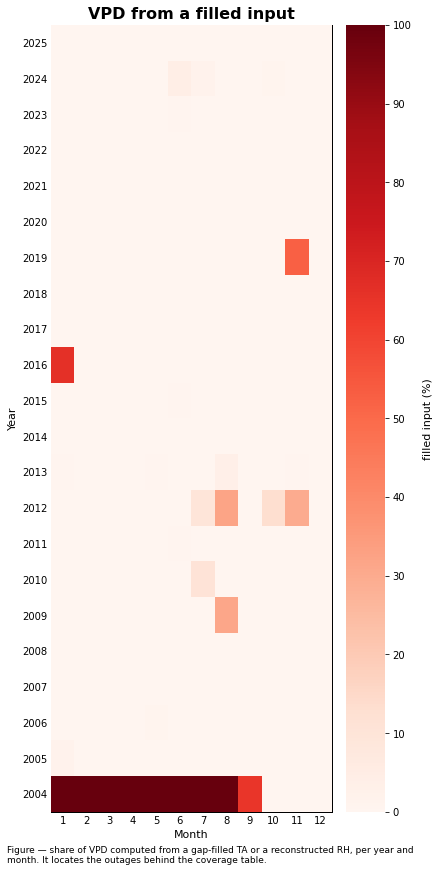

In [11]:
# Where the records from a filled or reconstructed input sit. A month that is largely such records
# says as much about the reconstruction as about the site.
fig, ax = plt.subplots(figsize=(6, 12), dpi=72, layout="constrained")
_filled_pct = (df[flagname].gt(0).astype(float) * 100).rename("filled input (%)")
dv.plotting.HeatmapYearMonth(series=_filled_pct, agg='mean').plot(
    ax=ax, cmap="Reds", zlabel="filled input (%)", cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title=f"{var} from a filled input", axlabel_fontsize=11,
                                         ticks_fontsize=10))
figcap(fig, f"share of {var} computed from a gap-filled TA or a reconstructed RH, per year and month. "
            f"It locates the outages behind the coverage table.")

</br>

# Summary statistics

## Overall mean

In [12]:
# Mean of the yearly means, with the standard deviation between years. The mean over all records
# is printed next to it: the two differ slightly because years have different lengths.
_yearly_avg = series.resample('YE').mean()
_overall_mean = _yearly_avg.mean()
_overall_sd = _yearly_avg.std()
print(f"Overall mean (mean of yearly means): {_overall_mean:.3f} {units} "
      f"+/- {_overall_sd:.3f} {units} SD between years")
print(f"Mean over all records:               {series.mean():.3f} {units}")
print(f"Computed from {varname} (homogenised).")

Overall mean (mean of yearly means): 0.341 kPa +/- 0.046 kPa SD between years
Mean over all records:               0.341 kPa
Computed from VPD_T1_47_1_HOMOGENIZED (homogenised).


## Yearly means

### 📋 Table: yearly statistics

In [13]:
# One table for the year-by-year view: the mean and its anomaly against the record, the mean daily
# maximum and the highest value of the year, its rank, two threshold-day counts detailed further
# below, and how much of it was computed from a filled or reconstructed input.
ym = per_year(series, 'mean')
_high = VPD_DRY_THRESHOLDS[1]

yearly = pd.DataFrame({
    f"mean ({units})": ym,
    f"mean daily maximum ({units})": per_year(daily['max'], 'mean'),
    f"maximum ({units})": per_year(series, 'max'),
    f"anomaly ({units})": ym - ym.mean(),
    "rank (driest first)": ym.rank(ascending=False).astype(int),
    f"days max >= {_high:g} {units}": per_year(daily['max'].ge(_high).astype(float), 'sum'),
    f"saturated days (max < {VPD_SATURATED:g} {units})": per_year(daily['max'].lt(VPD_SATURATED).astype(float), 'sum'),
    "filled input (%)": per_year(df[flagname].gt(0).astype(float), 'mean') * 100,
})

_fmt = {c: "{:.2f}" for c in yearly.columns}
_fmt.update({"rank (driest first)": "{:.0f}", "filled input (%)": "{:.1f}",
             f"days max >= {_high:g} {units}": "{:.0f}",
             f"saturated days (max < {VPD_SATURATED:g} {units})": "{:.0f}"})
_styler = styled(yearly, caption=f"{var} per year: the mean and its anomaly against the record, the mean "
                                 f"daily maximum and the highest half-hour, its rank, two threshold-day "
                                 f"counts detailed further below, and the share computed from a filled "
                                 f"or reconstructed input", fmt=_fmt,
                 subset=[f"mean ({units})", f"mean daily maximum ({units})", f"maximum ({units})"])
display(anomaly_bars(_styler, f"anomaly ({units})"))

Table — VPD per year: the mean and its anomaly against the record, the mean daily maximum and the
highest half-hour, its rank, two threshold-day counts detailed further below, and the share computed
from a filled or reconstructed input



,mean (kPa),mean daily maximum (kPa),maximum (kPa),anomaly (kPa),rank (driest first),days max >= 2 kPa,saturated days (max < 0.1 kPa),filled input (%)
YEAR,,,,,,,,
2004,0.32,0.65,2.81,-0.02,11,11,59,72.0
2005,0.32,0.64,3.02,-0.02,12,23,73,0.2
2006,0.33,0.68,3.43,-0.01,10,21,61,0.2
2007,0.32,0.66,3.25,-0.02,14,11,46,0.1
2008,0.29,0.60,2.43,-0.05,20,7,50,0.1
2009,0.32,0.67,2.86,-0.02,13,13,54,2.8
2010,0.29,0.60,2.93,-0.05,19,15,79,1.0
2011,0.37,0.75,3.10,0.03,8,13,54,0.1
2012,0.31,0.65,3.19,-0.03,16,14,81,7.2


## Period means

In [14]:
# Means of the yearly means, on the same basis as the overall mean above. The record is split into
# the most recent N_RECENT_YEARS and everything before them, and the earlier period is the reference
# the recent one is compared against. The split follows the record, so it moves on as the dataset
# grows. Both boundary years are included.
_first_recent = ym.index.max() - N_RECENT_YEARS + 1
assert _first_recent > ym.index.min(), "not enough years before the recent period"
_early = (ym.index.min(), _first_recent - 1)
_recent = (_first_recent, ym.index.max())

_early_mean = ym.loc[_early[0]:_early[1]].mean()
_recent_mean = ym.loc[_recent[0]:_recent[1]].mean()
print(f"Average {var} {_early[0]}-{_early[1]}: {_early_mean:.3f} {units}")
print(f"Average {var} {_recent[0]}-{_recent[1]}: {_recent_mean:.3f} {units} "
      f"({_recent_mean - _early_mean:+.3f} {units}, {100 * (_recent_mean / _early_mean - 1):+.1f} % "
      f"compared to {_early[0]}-{_early[1]})")

# The same difference on the measured column, to show how much of it depends on the homogenisation.
_ym_meas = per_year(df[varname_measured], 'mean')
_early_meas = _ym_meas.loc[_early[0]:_early[1]].mean()
_recent_meas = _ym_meas.loc[_recent[0]:_recent[1]].mean()
print(f"\nOn the measured column the same difference is {_recent_meas - _early_meas:+.3f} {units}.")

Average VPD 2004-2015: 0.324 kPa
Average VPD 2016-2025: 0.361 kPa (+0.037 kPa, +11.4 % compared to 2004-2015)

On the measured column the same difference is +0.027 kPa.


## Driest and most humid years

In [15]:
# The full ranking is the `rank` column of the yearly table above; this lists the two ends of it.
for _label, _ranked in [(f"{N_RANKED} driest years", ym.nlargest(N_RANKED)),
                        (f"{N_RANKED} most humid years", ym.nsmallest(N_RANKED))]:
    print(f"{_label}: " + ", ".join(f"{_year} ({_mean:.3f} {units})" for _year, _mean in _ranked.items()))

5 driest years: 2022 (0.429 kPa), 2018 (0.415 kPa), 2015 (0.406 kPa), 2020 (0.396 kPa), 2019 (0.386 kPa)
5 most humid years: 2024 (0.282 kPa), 2021 (0.284 kPa), 2008 (0.287 kPa), 2010 (0.294 kPa), 2013 (0.300 kPa)


</br>

# Seasonality

## Monthly means per year

### 📋 Table: monthly means per year

In [16]:
# Monthly means, one row per year. The colour scale runs over the whole table, so a month can be
# compared against every other month as well as against the same month in other years.
monthly_avg = per_year_month(series, 'mean')
display(styled(monthly_avg, caption=f"monthly mean {var} ({units}), one row per year. The colour scale runs "
                                    f"over the whole table, so the seasonal cycle dominates it and an "
                                    f"unusual month shows against its own column", axis=None))

Table — monthly mean VPD (kPa), one row per year. The colour scale runs over the whole table, so the
seasonal cycle dominates it and an unusual month shows against its own column



,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
YEAR,,,,,,,,,,,,
2004,0.05,0.18,0.24,0.42,0.50,0.58,0.62,0.55,0.44,0.19,0.06,0.04
2005,0.08,0.06,0.24,0.35,0.55,0.80,0.63,0.41,0.37,0.21,0.11,0.03
2006,0.05,0.06,0.11,0.28,0.39,0.73,1.11,0.28,0.40,0.24,0.21,0.10
2007,0.08,0.14,0.22,0.81,0.51,0.45,0.55,0.44,0.31,0.17,0.08,0.04
2008,0.15,0.20,0.17,0.23,0.61,0.50,0.62,0.45,0.23,0.15,0.09,0.04
2009,0.05,0.08,0.14,0.51,0.56,0.46,0.57,0.68,0.38,0.21,0.13,0.06
2010,0.03,0.11,0.26,0.48,0.26,0.58,0.76,0.40,0.34,0.19,0.08,0.04
2011,0.07,0.16,0.30,0.67,0.72,0.52,0.53,0.70,0.42,0.15,0.13,0.05
2012,0.04,0.09,0.44,0.34,0.53,0.50,0.52,0.66,0.31,0.18,0.07,0.05


## Climatology per calendar month

### 📋 Table: climatology per calendar month

In [17]:
# The same monthly means read the other way round: what each calendar month looks like across the
# record, and which year holds its extremes. The record high is a half-hourly value, so it lies far
# above any monthly mean.
_daily_max_month = per_year_month(daily['max'], 'mean')
_records_high = series.groupby(series.index.month).max()

climatology = pd.DataFrame({
    f"mean ({units})": monthly_avg.mean(),
    f"SD between years ({units})": monthly_avg.std(),
    f"most humid year mean ({units})": monthly_avg.min(),
    "most humid year": monthly_avg.idxmin(),
    f"driest year mean ({units})": monthly_avg.max(),
    "driest year": monthly_avg.idxmax(),
    f"mean daily maximum ({units})": _daily_max_month.mean(),
    # Both frames run January to December, so the month numbers align with the month names.
    f"record high ({units})": _records_high.to_numpy(),
})
climatology.index.name = "MONTH"

_fmt = {c: "{:.2f}" for c in climatology.columns}
_fmt.update({"most humid year": "{:.0f}", "driest year": "{:.0f}"})
display(styled(climatology, caption=f"the same monthly means read per calendar month: the long-term mean, the "
                                    f"spread between years, which year holds each month's extremes, the "
                                    f"mean daily maximum and the half-hourly record high of that month",
               fmt=_fmt, subset=[c for c in climatology.columns if c.endswith(f"({units})")]))

Table — the same monthly means read per calendar month: the long-term mean, the spread between
years, which year holds each month's extremes, the mean daily maximum and the half-hourly record
high of that month



,mean (kPa),SD between years (kPa),most humid year mean (kPa),most humid year,driest year mean (kPa),driest year,mean daily maximum (kPa),record high (kPa)
MONTH,,,,,,,,
Jan,0.06,0.03,0.03,2010,0.15,2008,0.15,0.86
Feb,0.12,0.06,0.03,2018,0.26,2019,0.27,1.39
Mar,0.26,0.10,0.11,2006,0.51,2022,0.53,1.69
Apr,0.44,0.17,0.20,2023,0.81,2007,0.84,2.76
May,0.47,0.13,0.22,2013,0.72,2011,0.93,2.86
Jun,0.63,0.18,0.35,2016,0.99,2023,1.21,3.58
Jul,0.74,0.23,0.39,2021,1.18,2015,1.40,3.82
Aug,0.63,0.19,0.28,2006,0.94,2018,1.24,4.18
Sep,0.38,0.11,0.23,2008,0.62,2023,0.82,2.43


## Mean annual cycle

### 📊 Plot: mean annual cycle

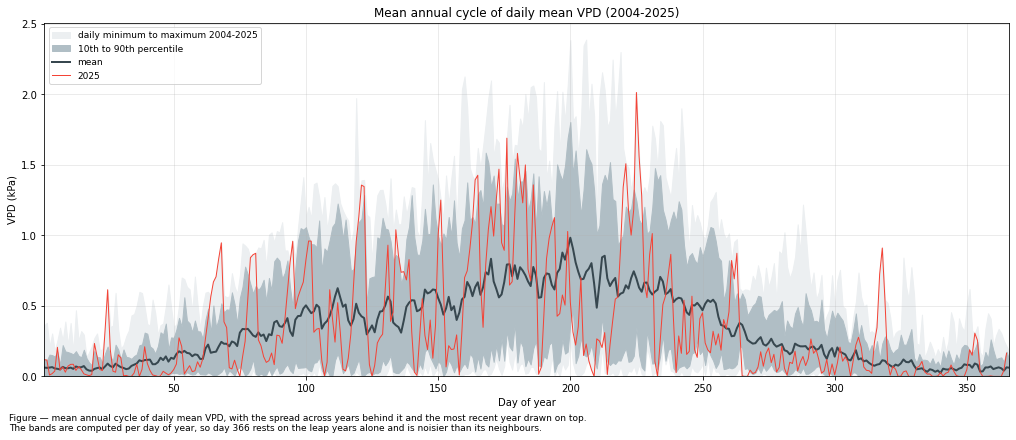

In [18]:
# Mean annual cycle of the daily mean, with the spread across years behind it and the most recent
# year drawn on top. The bands are computed per day of year, so day 366 rests on the leap years
# only and is noisier than its neighbours.
_doy = daily['mean'].groupby(daily.index.dayofyear)
_x = _doy.mean().index

fig, ax = plt.subplots(figsize=(14, 6), dpi=72, layout="constrained")
ax.fill_between(_x, _doy.min(), _doy.max(), color='#ECEFF1',
                label=f"daily minimum to maximum {FIRST_YEAR}-{LAST_YEAR}")
ax.fill_between(_x, _doy.quantile(0.1), _doy.quantile(0.9), color='#B0BEC5',
                label="10th to 90th percentile")
ax.plot(_x, _doy.mean(), color='#37474F', lw=2, label="mean")
_last_year = daily['mean'].loc[str(LAST_YEAR)]
ax.plot(_last_year.index.dayofyear, _last_year.to_numpy(), color='#F44336', lw=1, label=str(LAST_YEAR))
ax.set_xlabel("Day of year")
ax.set_ylabel(xlabel)
ax.set_title(f"Mean annual cycle of daily mean {var} ({FIRST_YEAR}-{LAST_YEAR})")
ax.set_xlim(1, 366)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(loc='upper left', fontsize=9)
figcap(fig, f"mean annual cycle of daily mean {var}, with the spread across years behind it and the "
            f"most recent year drawn on top. The bands are computed per day of year, so day 366 rests "
            f"on the leap years alone and is noisier than its neighbours.")
fig.show()

## Recent period against the earlier years, per month

### 📋 Table: recent period against the earlier years, per month

In [19]:
# The two periods of the period means, resolved by calendar month: which months carry the
# difference between them. A difference here is not a trend estimate, it is the distance between
# two averages; the trends are further below.
_split = monthly_avg.index.max() - N_RECENT_YEARS + 1
_early_label = f"{monthly_avg.index.min()}-{_split - 1} ({units})"
_recent_label = f"{_split}-{monthly_avg.index.max()} ({units})"
_difference_label = f"difference ({units})"

comparison = pd.DataFrame({
    _early_label: monthly_avg.loc[:_split - 1].mean(),
    _recent_label: monthly_avg.loc[_split:].mean(),
})
comparison[_difference_label] = comparison[_recent_label] - comparison[_early_label]
comparison.index.name = "MONTH"

_styler = styled(comparison, caption=f"the two periods of the period means resolved by calendar month, with "
                                     f"the difference between them. It shows which part of the year "
                                     f"carries that difference; it is a distance between two averages, "
                                     f"not a trend estimate",
                 subset=[_early_label, _recent_label])
display(anomaly_bars(_styler, _difference_label))

Table — the two periods of the period means resolved by calendar month, with the difference between
them. It shows which part of the year carries that difference; it is a distance between two
averages, not a trend estimate



,2004-2015 (kPa),2016-2025 (kPa),difference (kPa)
MONTH,,,
Jan,0.06,0.06,-0.01
Feb,0.11,0.14,0.03
Mar,0.24,0.29,0.05
Apr,0.44,0.44,0.00
May,0.48,0.45,-0.02
Jun,0.60,0.67,0.07
Jul,0.70,0.78,0.07
Aug,0.54,0.73,0.19
Sep,0.35,0.43,0.08


## Mean diurnal cycle per month

### 📊 Plot: mean diurnal cycle per month

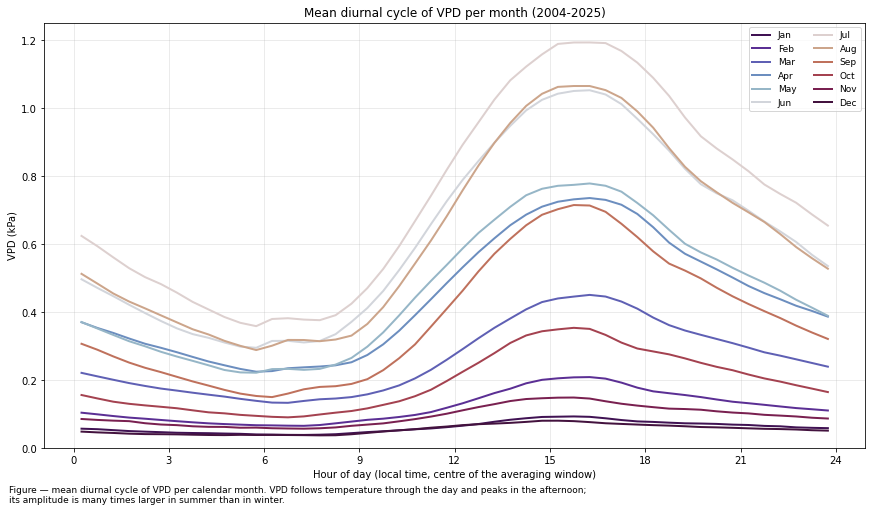

In [20]:
# Mean diurnal cycle per calendar month. The x axis is the centre of each 30MIN window, so the
# first point of the day is 00:15 and the last is 23:45.
_diurnal = series.groupby([series.index.month,
                           series.index.hour + series.index.minute / 60]).mean().unstack(0)

fig, ax = plt.subplots(figsize=(12, 7), dpi=72, layout="constrained")
_colors = plt.get_cmap('twilight_shifted')(np.linspace(0.05, 0.95, len(_diurnal.columns)))
for _i, _month in enumerate(_diurnal.columns):
    ax.plot(_diurnal.index, _diurnal[_month], color=_colors[_i], lw=2,
            label=calendar.month_abbr[_month])
ax.set_xlabel("Hour of day (local time, centre of the averaging window)")
ax.set_ylabel(xlabel)
ax.set_title(f"Mean diurnal cycle of {var} per month ({FIRST_YEAR}-{LAST_YEAR})")
ax.set_xticks(range(0, 25, 3))
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(ncol=2, fontsize=9)
figcap(fig, f"mean diurnal cycle of {var} per calendar month. VPD follows temperature through the day "
            f"and peaks in the afternoon; its amplitude is many times larger in summer than in winter.")
fig.show()

## Month by hour

### 📊 Plot: month by hour

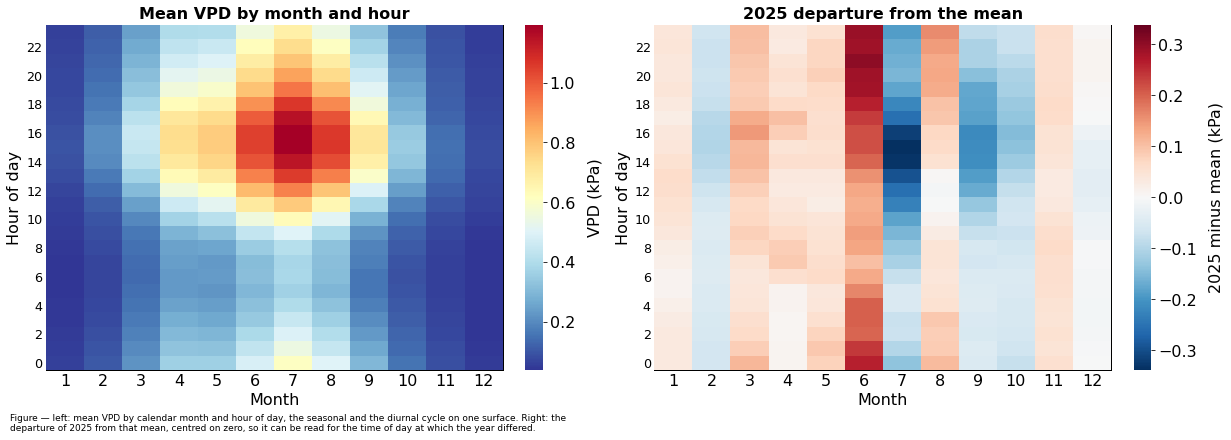

In [21]:
# The same cycle as a surface, next to the departure of the most recent year from it. The right
# panel is centred on zero, so red and blue are equal distances from the long-term mean.
def _by_month_hour(s):
    """Mean of `s` per calendar month and hour, in the long form HeatmapXYZ expects."""
    frame = pd.DataFrame({'MONTH': s.index.month, 'HOUR': s.index.hour, 'z': s.to_numpy()})
    return frame.groupby(['MONTH', 'HOUR'], as_index=False)['z'].mean()


_clim_hm = _by_month_hour(series)
_last_hm = _by_month_hour(series.loc[str(LAST_YEAR)])
_anomaly_hm = _clim_hm.copy()
_anomaly_hm['z'] = _last_hm['z'].to_numpy() - _clim_hm['z'].to_numpy()
_absmax = _anomaly_hm['z'].abs().max()

fig, axs = plt.subplots(ncols=2, figsize=(17, 6), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_clim_hm['MONTH'], y=_clim_hm['HOUR'], z=_clim_hm['z']).plot(
    ax=axs[0],
    xlabel="Month", ylabel="Hour of day", zlabel=f"{var} ({units})",
    format_style=dv.plotting.FormatStyle(title=f"Mean {var} by month and hour"))
dv.plotting.HeatmapXYZ(x=_anomaly_hm['MONTH'], y=_anomaly_hm['HOUR'], z=_anomaly_hm['z']).plot(
    ax=axs[1], cmap='RdBu_r', vmin=-_absmax, vmax=_absmax,
    xlabel="Month", ylabel="Hour of day", zlabel=f"{LAST_YEAR} minus mean ({units})",
    format_style=dv.plotting.FormatStyle(title=f"{LAST_YEAR} departure from the mean"))
figcap(fig, f"left: mean {var} by calendar month and hour of day, the seasonal and the diurnal cycle "
            f"on one surface. Right: the departure of {LAST_YEAR} from that mean, centred on zero, so "
            f"it can be read for the time of day at which the year differed.")

</br>

# Extremes and threshold days

::: {.callout-note title="The low end depends on the probe"}

VPD is zero where `RH` reaches 100 %, and how often a probe reports saturation is a property of the
probe as well as of the air. The homogenised column reaches exactly 0 kPa far more often before 2016
than after it (*Half-hours at saturation* below), so counts of saturated half-hours are not
comparable across January 2016. Counts on the daily maximum are much less affected: a day counts as
saturated only if it stays below 0.1 kPa throughout, and the high-end thresholds are far from zero.

:::

## Highest half-hourly value

In [22]:
# The highest value of the homogenised series, marked by what it was computed from. The averaging
# window is reported instead of the timestamp, because the product is stored on TIMESTAMP_MIDDLE.
# The lowest value is zero, at saturation, and is reported as a count instead.
_tsmid = series.idxmax()
print(f"Highest {var}: {series.loc[_tsmid]:.2f} {units} ({window(_tsmid)}), {provenance(_tsmid)}")
print(f"Lowest {var}:  {series.min():.2f} {units}, in {int(series.eq(0).sum()):,} half-hours")

Highest VPD: 4.18 kPa (07 Aug 2015, 17:00 to 17:30), measured TA and RH
Lowest VPD:  0.00 kPa, in 25,610 half-hours


## The driest half-hours and days

### 📋 Table: the driest half-hours

In [23]:
# The extreme above in context. Neighbouring half-hours of the same afternoon fill this list, which
# is the point: a record half-hour is part of an episode, not an isolated reading.
_ranked = series.nlargest(N_EXTREMES)
_table = pd.DataFrame({"averaging window": [window(_ts) for _ts in _ranked.index],
                       f"{var} ({units})": _ranked.to_numpy(),
                       "computed from": [provenance(_ts) for _ts in _ranked.index]},
                      index=range(1, N_EXTREMES + 1))
_table.index.name = "rank"
display(styled(_table, caption=f"the {N_EXTREMES} driest half-hours of the homogenised series with their "
                               f"averaging windows and what each was computed from. Neighbouring "
                               f"windows of a single afternoon fill the list, which is what an episode "
                               f"looks like at this resolution",
               subset=[f"{var} ({units})"]))

Table — the 10 driest half-hours of the homogenised series with their averaging windows and what
each was computed from. Neighbouring windows of a single afternoon fill the list, which is what an
episode looks like at this resolution



,averaging window,VPD (kPa),computed from
rank,,,
1,"07 Aug 2015, 17:00 to 17:30",4.18,measured TA and RH
2,"07 Aug 2015, 16:30 to 17:00",4.16,measured TA and RH
3,"07 Aug 2015, 16:00 to 16:30",3.95,measured TA and RH
4,"07 Aug 2015, 17:30 to 18:00",3.92,measured TA and RH
5,"24 Jul 2019, 16:00 to 16:30",3.82,measured TA and RH
6,"06 Aug 2015, 17:30 to 18:00",3.80,measured TA and RH
7,"24 Jul 2019, 18:00 to 18:30",3.79,measured TA and RH
8,"24 Jul 2019, 16:30 to 17:00",3.78,measured TA and RH
9,"07 Aug 2015, 18:00 to 18:30",3.78,measured TA and RH


### 📋 Table: the driest days

In [24]:
# The same for daily means. A daily mean is computed over all records of the day, so the share
# computed from a filled or reconstructed input is listed next to it.
_ranked = daily['mean'].nlargest(N_EXTREMES)
_table = pd.DataFrame({"date": [f"{_day:%d %b %Y}" for _day in _ranked.index],
                       f"daily mean {var} ({units})": _ranked.to_numpy(),
                       f"daily maximum {var} ({units})": daily.loc[_ranked.index, 'max'].to_numpy(),
                       "filled input (%)": daily.loc[_ranked.index, 'filled input (%)'].to_numpy()},
                      index=range(1, N_EXTREMES + 1))
_table.index.name = "rank"
display(styled(_table, caption=f"the {N_EXTREMES} driest days by daily mean, with their daily maximum and the "
                               f"share of each day computed from a filled or reconstructed input",
               fmt={f"daily mean {var} ({units})": "{:.2f}", f"daily maximum {var} ({units})": "{:.2f}",
                    "filled input (%)": "{:.1f}"},
               subset=[f"daily mean {var} ({units})", f"daily maximum {var} ({units})"]))

Table — the 10 driest days by daily mean, with their daily maximum and the share of each day
computed from a filled or reconstructed input



,date,daily mean VPD (kPa),daily maximum VPD (kPa),filled input (%)
rank,,,,
1,25 Jul 2019,2.39,3.67,0.0
2,19 Jul 2022,2.39,3.45,0.0
3,24 Jul 2019,2.35,3.82,0.0
4,07 Aug 2015,2.30,4.18,0.0
5,19 Jul 2006,2.25,3.43,0.0
6,04 Aug 2022,2.25,3.69,0.0
7,31 Jul 2018,2.16,3.28,0.0
8,25 Jul 2006,2.13,3.34,0.0
9,09 Jun 2014,2.13,3.57,0.0


## Half-hours at saturation

### 📋 Table: half-hours at saturation per year

In [25]:
# Half-hours at exactly 0 kPa, where RH reached 100 %, per year and on both columns. The counts
# depend on how each probe reports humidity near saturation and on the homogenisation of RH, which
# is why the saturated half-hours are not read as a climate statistic in this notebook.
saturation = pd.DataFrame({
    "homogenised": per_year(series.eq(0).astype(float), 'sum'),
    "as measured": per_year(df[varname_measured].eq(0).astype(float), 'sum'),
})
display(styled(saturation, caption=f"half-hours per year at exactly 0 {units} (RH at 100 %), on the "
                                   f"homogenised and the measured column. The difference between the "
                                   f"probe eras is larger than any difference between years",
               fmt="{:.0f}", cmap="Blues", axis=None))

Table — half-hours per year at exactly 0 kPa (RH at 100 %), on the homogenised and the measured
column. The difference between the probe eras is larger than any difference between years



,homogenised,as measured
YEAR,,
2004,1192,373
2005,1651,0
2006,1594,6
2007,1406,26
2008,2217,0
2009,1919,12
2010,2341,87
2011,2057,265
2012,2855,104


## Threshold days

### 📋 Table: threshold days per year

In [26]:
# Threshold-day counts per year. The thresholds are set in the Settings cell and are stated in the
# column names, because the counts mean nothing without them. The counts come from daily maxima and
# means of the complete series.
indices = pd.DataFrame({
    f"days max >= {_t:g} {units}": per_year(daily['max'].ge(_t).astype(float), 'sum')
    for _t in VPD_DRY_THRESHOLDS})
indices[f"days mean >= {VPD_MEAN_THRESHOLD:g} {units}"] = per_year(
    daily['mean'].ge(VPD_MEAN_THRESHOLD).astype(float), 'sum')
indices[f"saturated days (max < {VPD_SATURATED:g} {units})"] = per_year(
    daily['max'].lt(VPD_SATURATED).astype(float), 'sum')
display(styled(indices, caption=f"threshold days per year: days whose maximum reached each of the dry "
                                f"thresholds, days whose mean did, and days that stayed at or near "
                                f"saturation throughout", fmt="{:.0f}"))

Table — threshold days per year: days whose maximum reached each of the dry thresholds, days whose
mean did, and days that stayed at or near saturation throughout



,days max >= 1 kPa,days max >= 2 kPa,days max >= 3 kPa,days mean >= 1 kPa,saturated days (max < 0.1 kPa)
YEAR,,,,,
2004,94,11,0,18,59
2005,81,23,2,25,73
2006,85,21,4,28,61
2007,95,11,1,22,46
2008,81,7,0,13,50
2009,94,13,0,16,54
2010,78,15,0,26,79
2011,115,13,3,30,54
2012,97,14,2,16,81


### 📊 Plot: threshold days per year

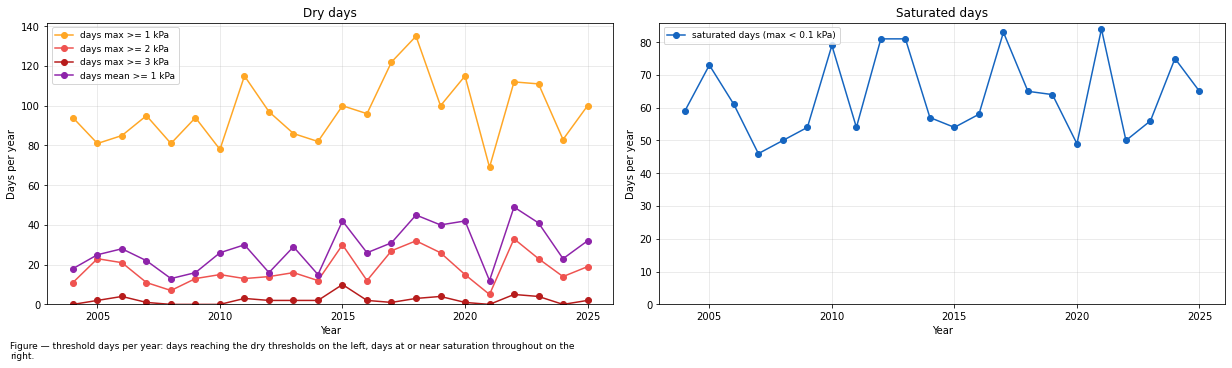

In [27]:
# Dry and saturated days are drawn apart, because they describe the two ends of the distribution.
_dry_cols = [c for c in indices.columns if not c.startswith("saturated")]
_sat_col = [c for c in indices.columns if c.startswith("saturated")]
fig, axs = plt.subplots(ncols=2, figsize=(17, 5), dpi=72, layout="constrained")
indices[_dry_cols].plot(ax=axs[0], marker='o', lw=1.5,
                        color=['#FFA726', '#EF5350', '#B71C1C', '#8E24AA'])
indices[_sat_col].plot(ax=axs[1], marker='o', lw=1.5, color=['#1565C0'])
for _ax, _title in [(axs[0], "Dry days"), (axs[1], "Saturated days")]:
    _ax.set_title(_title)
    _ax.set_xlabel("Year")
    _ax.set_ylabel("Days per year")
    _ax.set_ylim(bottom=0)
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
figcap(fig, "threshold days per year: days reaching the dry thresholds on the left, days at or near "
            "saturation throughout on the right.")

## Dry and saturated spells

### 📋 Table: longest dry and saturated spell per year

In [28]:
# The longest dry and saturated spells of each year: how long a threshold was held without a break,
# and when the spell started. A year can collect many dry days without ever holding them for a
# week, and the two say different things about the season.
_rows = {}
for _year, _day in daily.groupby(daily.index.year):
    _dry_len, _dry_start = longest_spell(_day['max'].ge(VPD_SPELL))
    _sat_len, _sat_start = longest_spell(_day['max'].lt(VPD_SATURATED))
    _rows[_year] = {"dry spell (days)": _dry_len,
                    "dry spell start": "-" if pd.isna(_dry_start) else f"{_dry_start:%d %b}",
                    "saturated spell (days)": _sat_len,
                    "saturated spell start": "-" if pd.isna(_sat_start) else f"{_sat_start:%d %b}"}
spells = pd.DataFrame.from_dict(_rows, orient='index')
spells.index.name = "YEAR"

display(styled(spells, caption=f"the longest uninterrupted run of days with a daily maximum of at least "
                               f"{VPD_SPELL:g} {units} (dry spell) and below {VPD_SATURATED:g} {units} "
                               f"(saturated spell) in each year, with its start date",
               fmt="{:.0f}"))

Table — the longest uninterrupted run of days with a daily maximum of at least 2 kPa (dry spell) and
below 0.1 kPa (saturated spell) in each year, with its start date



,dry spell (days),dry spell start,saturated spell (days),saturated spell start
YEAR,,,,
2004,5,30 Jul,9,05 Dec
2005,6,19 Jun,10,14 Feb
2006,12,16 Jul,6,21 Dec
2007,3,14 Jul,6,16 Dec
2008,2,22 Jun,6,16 Dec
2009,2,24 May,11,01 Jan
2010,3,08 Jul,12,05 Jan
2011,4,21 Aug,10,25 Jan
2012,3,18 Aug,17,27 Nov


</br>

# Distributions

Ridgeline plots of the half-hourly values per year and per month, then the same distributions read
as percentiles.

## Ridgelines per year

### 📊 Plot: distribution per year

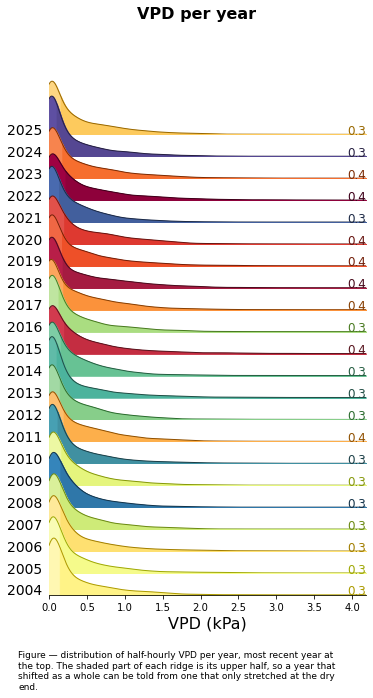

In [29]:
# The kernel bandwidth is set to 0.1 kPa: the default of 1 suits a quantity spanning tens of units
# and would smooth the 0-4 kPa range of VPD into a single flat hump.
KD_KWARGS = {'bandwidth': 0.1}
rp = dv.plotting.RidgeLinePlot(series=series)
rp.plot(
    how='yearly',
    kd_kwargs=KD_KWARGS,  # params from scikit KernelDensity as dict
    xlim=xlim,  # min/max as list
    ylim=[0, 4],  # min/max as list
    hspace=-0.8,  # overlap between years
    fig_width=5,
    fig_height=9,
    shade_percentile=0.5,
    show_mean_line=False,
    format_style=dv.plotting.FormatStyle(xlabel=xlabel, title=f"{var} per year"),
    fig_dpi=72,
    showplot=True,
    ascending=False
)
figcap(rp.fig, f"distribution of half-hourly {var} per year, most recent year at the top. The shaded "
               f"part of each ridge is its upper half, so a year that shifted as a whole can be told "
               f"from one that only stretched at the dry end.")

## Ridgelines per month

### 📊 Plot: distribution per calendar month

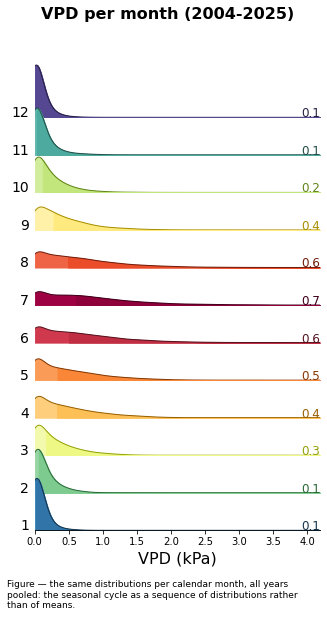

In [30]:
rp.plot(
    how='monthly',
    kd_kwargs=KD_KWARGS,  # params from scikit KernelDensity as dict
    xlim=xlim,  # min/max as list
    ylim=[0, 6],  # min/max as list
    hspace=-0.6,  # overlap between months
    fig_width=4.5,
    fig_height=8,
    shade_percentile=0.5,
    show_mean_line=False,
    format_style=dv.plotting.FormatStyle(xlabel=xlabel,
                                         title=f"{var} per month ({FIRST_YEAR}-{LAST_YEAR})"),
    fig_dpi=72,
    showplot=True,
    ascending=False
)
figcap(rp.fig, f"the same distributions per calendar month, all years pooled: the seasonal cycle as a "
               f"sequence of distributions rather than of means.")

## Percentiles per year

### 📊 Plot: percentiles per year

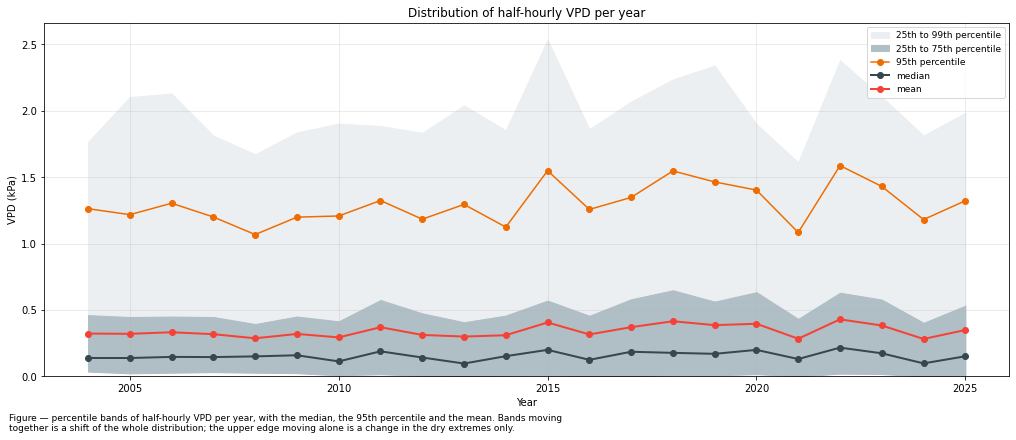

In [31]:
# Quantiles of the half-hourly values per year. The ridgelines above show the shape of each year's
# distribution; this shows where its upper part moved. The lower percentiles sit close to zero in
# every year, so a change of VPD shows in the median and above.
QUANTILES = [0.25, 0.5, 0.75, 0.95, 0.99]
quantiles = series.groupby(series.index.year).quantile(QUANTILES).unstack()
quantiles.index.name = "YEAR"

fig, ax = plt.subplots(figsize=(14, 6), dpi=72, layout="constrained")
ax.fill_between(quantiles.index, quantiles[0.25], quantiles[0.99], color='#ECEFF1',
                label="25th to 99th percentile")
ax.fill_between(quantiles.index, quantiles[0.25], quantiles[0.75], color='#B0BEC5',
                label="25th to 75th percentile")
ax.plot(quantiles.index, quantiles[0.95], color='#EF6C00', lw=1.5, marker='o', label="95th percentile")
ax.plot(quantiles.index, quantiles[0.5], color='#37474F', lw=2, marker='o', label="median")
ax.plot(ym.index, ym, color='#F44336', lw=2, marker='o', label="mean")
ax.set_xlabel("Year")
ax.set_ylabel(xlabel)
ax.set_title(f"Distribution of half-hourly {var} per year")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
figcap(fig, f"percentile bands of half-hourly {var} per year, with the median, the 95th percentile and "
            f"the mean. Bands moving together is a shift of the whole distribution; the upper edge "
            f"moving alone is a change in the dry extremes only.")
fig.show()

### 📋 Table: percentiles per year

In [32]:
_table = quantiles.copy()
_table.columns = [f"{int(q * 100)}th percentile ({units})" for q in _table.columns]
display(styled(_table, caption=f"percentiles of half-hourly {var} per year, the numbers behind the bands: "
                               f"whether a year moved as a whole or only at the dry end"))

Table — percentiles of half-hourly VPD per year, the numbers behind the bands: whether a year moved
as a whole or only at the dry end



,25th percentile (kPa),50th percentile (kPa),75th percentile (kPa),95th percentile (kPa),99th percentile (kPa)
YEAR,,,,,
2004,0.04,0.14,0.46,1.26,1.77
2005,0.02,0.14,0.45,1.22,2.10
2006,0.03,0.15,0.45,1.30,2.13
2007,0.03,0.15,0.45,1.20,1.81
2008,0.03,0.15,0.39,1.07,1.67
2009,0.02,0.16,0.45,1.20,1.84
2010,0.01,0.11,0.41,1.21,1.90
2011,0.02,0.19,0.58,1.32,1.89
2012,0.01,0.14,0.47,1.18,1.83


</br>

# Heatmap plots

## Half-hourly

### 📊 Plot: heatmap of the half-hourly values

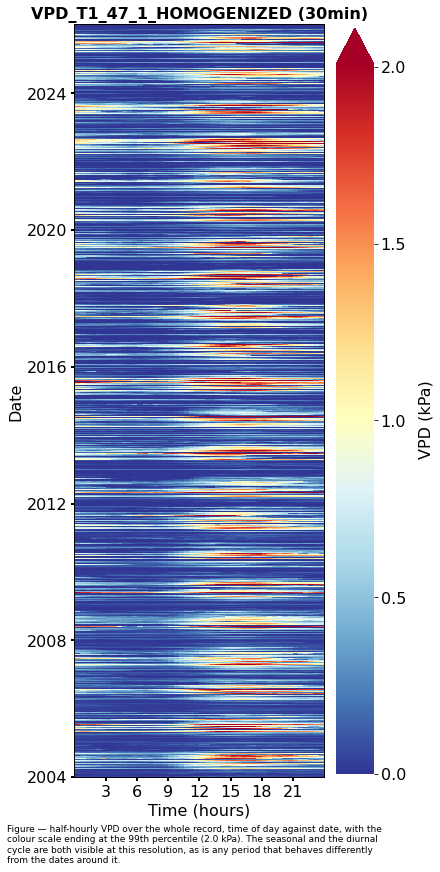

In [33]:
# The colour scale ends at the 99th percentile: VPD is skewed, and a scale up to the single driest
# half-hour would draw almost the whole record in its lowest colours.
_vmax = float(series.quantile(0.99))
fig, axs = plt.subplots(ncols=1, figsize=(6, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapDateTime(series=series).plot(ax=axs, zlabel=xlabel, vmin=0, vmax=_vmax,
                                                cb_extend='max')
figcap(fig, f"half-hourly {var} over the whole record, time of day against date, with the colour scale "
            f"ending at the 99th percentile ({_vmax:.1f} {units}). The seasonal and the diurnal cycle "
            f"are both visible at this resolution, as is any period that behaves differently from the "
            f"dates around it.")

## Monthly

### 📊 Plot: heatmaps of the monthly mean, mean daily maximum and maximum

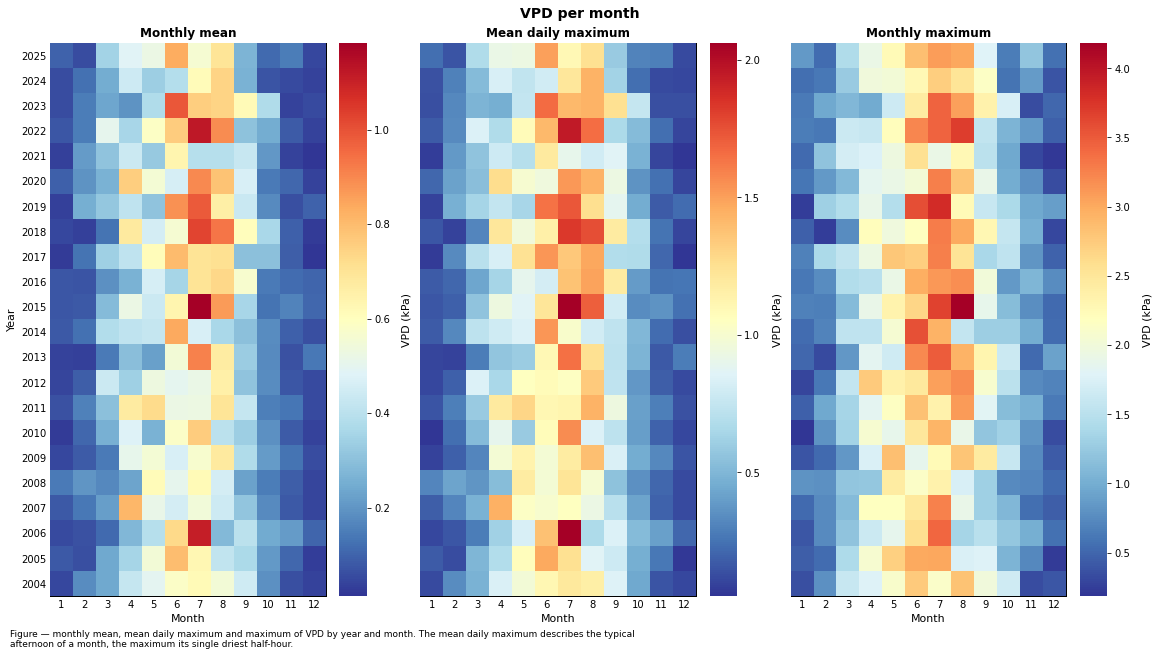

In [34]:
# Three panels: the monthly minimum is close to zero in every month and is left out.
fig, axs = plt.subplots(ncols=3, figsize=(16, 9), dpi=72, sharey=True, layout="constrained")
fig.suptitle(f'{var} per month', fontsize=14, fontweight='bold')
params = {'cb_labelsize': 10, 'zlabel': f"{var} ({units})",
          'format_style': dv.plotting.FormatStyle(axlabel_fontsize=11, ticks_fontsize=10)}

# HeatmapYearMonth aggregates the series itself: the half-hourly series for the mean and the
# maximum, the daily maxima for the mean daily maximum. The daily maxima are placed at noon, because
# a timestamp at midnight would be read as the end of the previous day.
_daily_max = daily['max'].rename(varname)
_daily_max.index = _daily_max.index + pd.Timedelta('12h')
dv.plotting.HeatmapYearMonth(series=series, agg='mean').plot(ax=axs[0], **params)
dv.plotting.HeatmapYearMonth(series=_daily_max, agg='mean').plot(ax=axs[1], **params)
dv.plotting.HeatmapYearMonth(series=series, agg='max').plot(ax=axs[2], **params)

for _ax, _title in zip(axs, ["Monthly mean", "Mean daily maximum", "Monthly maximum"]):
    _ax.set_title(_title, fontsize=12, fontweight='bold', color='black')
for _ax in axs[1:]:
    _ax.set_ylabel("")
figcap(fig, f"monthly mean, mean daily maximum and maximum of {var} by year and month. The mean daily "
            f"maximum describes the typical afternoon of a month, the maximum its single driest "
            f"half-hour.")

## Monthly ranks

### 📊 Plot: monthly means and maxima as ranks

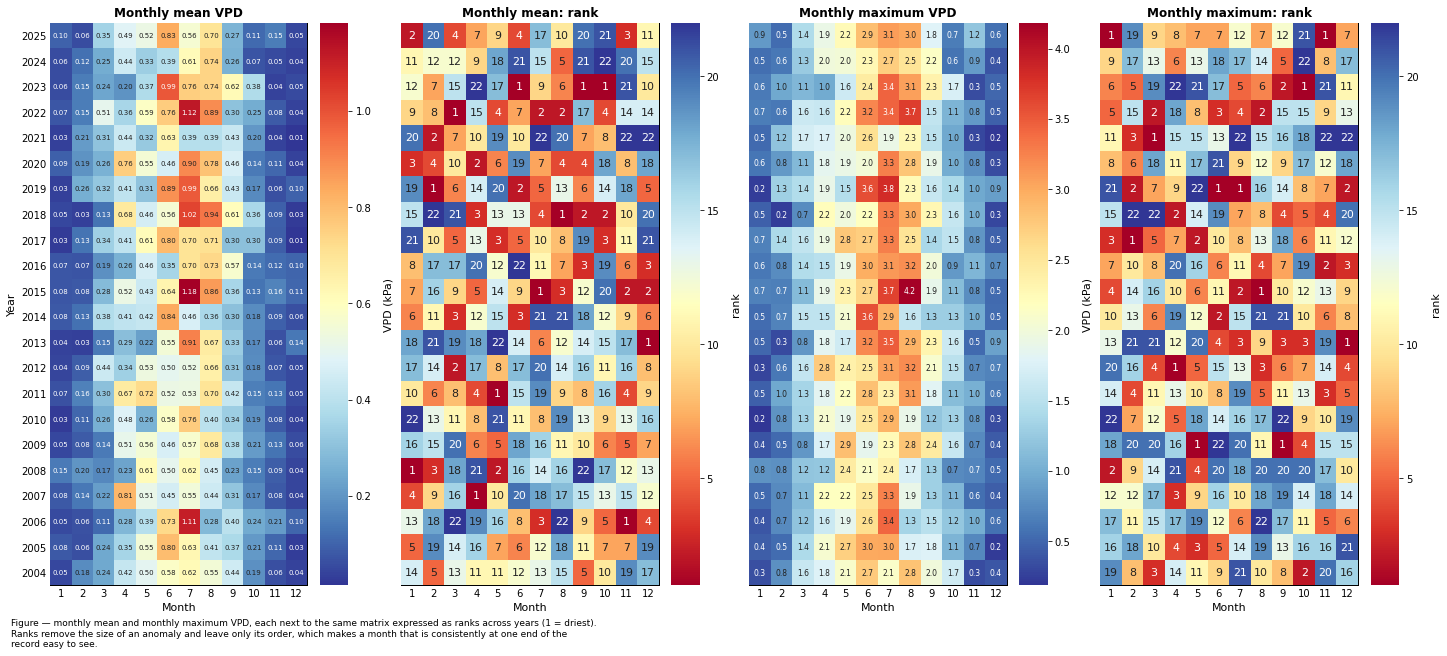

In [35]:
# Four panels side by side: monthly mean and monthly maximum, each next to its ranks across years
# (1 = driest). The panels share the year axis, so only the first one carries its labels.
fig, (ax_mean, ax_mean_ranks, ax_max, ax_max_ranks) = plt.subplots(
    ncols=4, figsize=(20, 9), dpi=72, sharey=True, layout="constrained")
params = {'show_values': True, 'cb_labelsize': 10,
          'format_style': dv.plotting.FormatStyle(axlabel_fontsize=11, ticks_fontsize=10)}

# The monthly means need two decimals, so their labels get a fixed size that fits the cells.
dv.plotting.HeatmapYearMonth(series=series, agg='mean', ranks=False).plot(
    ax=ax_mean, zlabel=f"{var} ({units})", cmap="RdYlBu_r", show_values_n_dec_places=2,
    show_values_fontsize=7, **params)
# Kept as a name: the ranks matrix is read back out of it further down.
hm_mean_ranks = dv.plotting.HeatmapYearMonth(series=series, agg='mean', ranks=True)
hm_mean_ranks.plot(ax=ax_mean_ranks, zlabel="rank", **params)
dv.plotting.HeatmapYearMonth(series=series, agg='max', ranks=False).plot(
    ax=ax_max, zlabel=f"{var} ({units})", cmap="RdYlBu_r", show_values_n_dec_places=1, **params)
dv.plotting.HeatmapYearMonth(series=series, agg='max', ranks=True).plot(
    ax=ax_max_ranks, zlabel="rank", **params)

for _ax, _title in [(ax_mean, f"Monthly mean {var}"), (ax_mean_ranks, "Monthly mean: rank"),
                    (ax_max, f"Monthly maximum {var}"), (ax_max_ranks, "Monthly maximum: rank")]:
    _ax.set_title(_title, fontsize=12, fontweight='bold', color='black')
for _ax in (ax_mean_ranks, ax_max, ax_max_ranks):
    _ax.set_ylabel("")
figcap(fig, f"monthly mean and monthly maximum {var}, each next to the same matrix expressed as ranks "
            f"across years (1 = driest). Ranks remove the size of an anomaly and leave only its "
            f"order, which makes a month that is consistently at one end of the record easy to see.")
fig.show()

### Mean ranks per year

#### 📊 Plot: mean rank per year

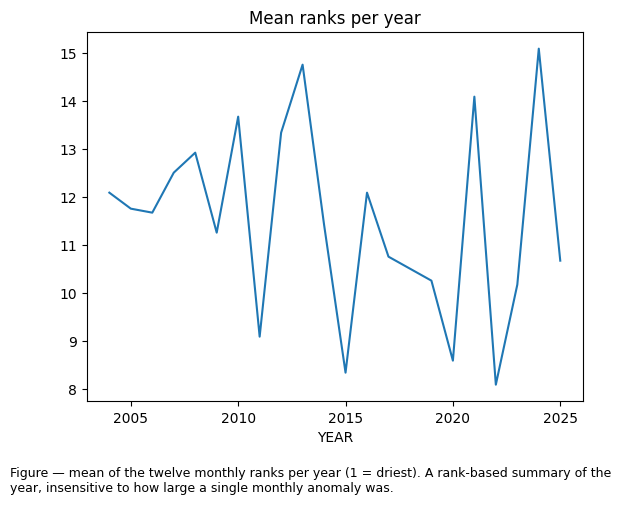

In [36]:
_ax = hm_mean_ranks.get_plot_data().mean(axis=1).plot(title="Mean ranks per year")
figcap(_ax.get_figure(), "mean of the twelve monthly ranks per year (1 = driest). A rank-based summary "
                         "of the year, insensitive to how large a single monthly anomaly was.")

</br>

# Anomalies and trends

## Per year

### 📊 Plot: yearly anomalies

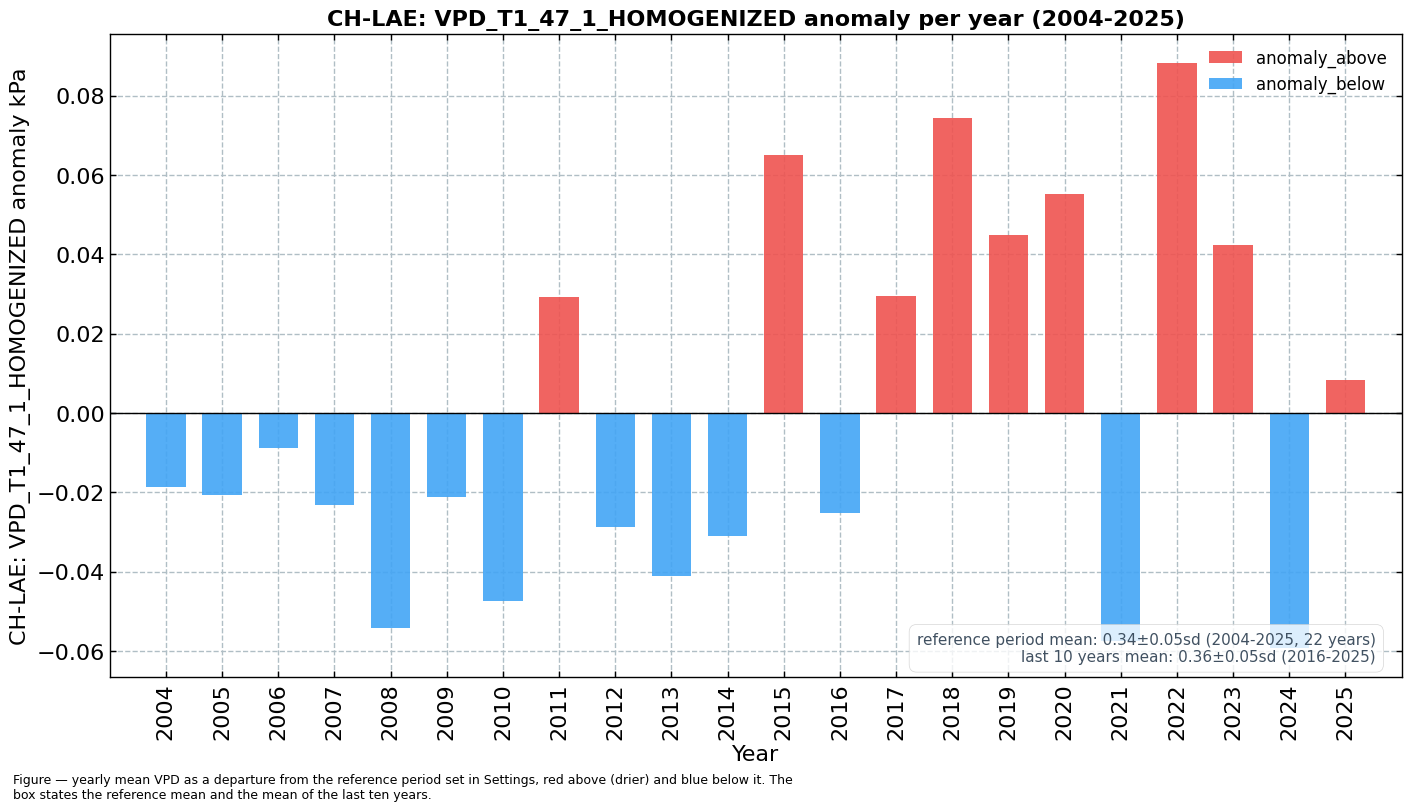

In [37]:
# Reference period from the Settings cell. It spans the whole record here, so the anomalies are
# departures from the record's own mean rather than from a climate normal such as 1991-2020, which
# this dataset is too short to provide.
series_label = f"CH-LAE: {varname}"
_anomalies_year = LongtermAnomaliesYear(series=ym,
                                        series_label=series_label,
                                        series_units=units,
                                        reference_start_year=REFERENCE_START_YEAR,
                                        reference_end_year=REFERENCE_END_YEAR)
_anomalies_year.plot()
figcap(_anomalies_year.fig,
       f"yearly mean {var} as a departure from the reference period set in Settings, red above (drier) "
       f"and blue below it. The box states the reference mean and the mean of the last ten years.")

## Per calendar month

### 📊 Plot: anomalies per calendar month

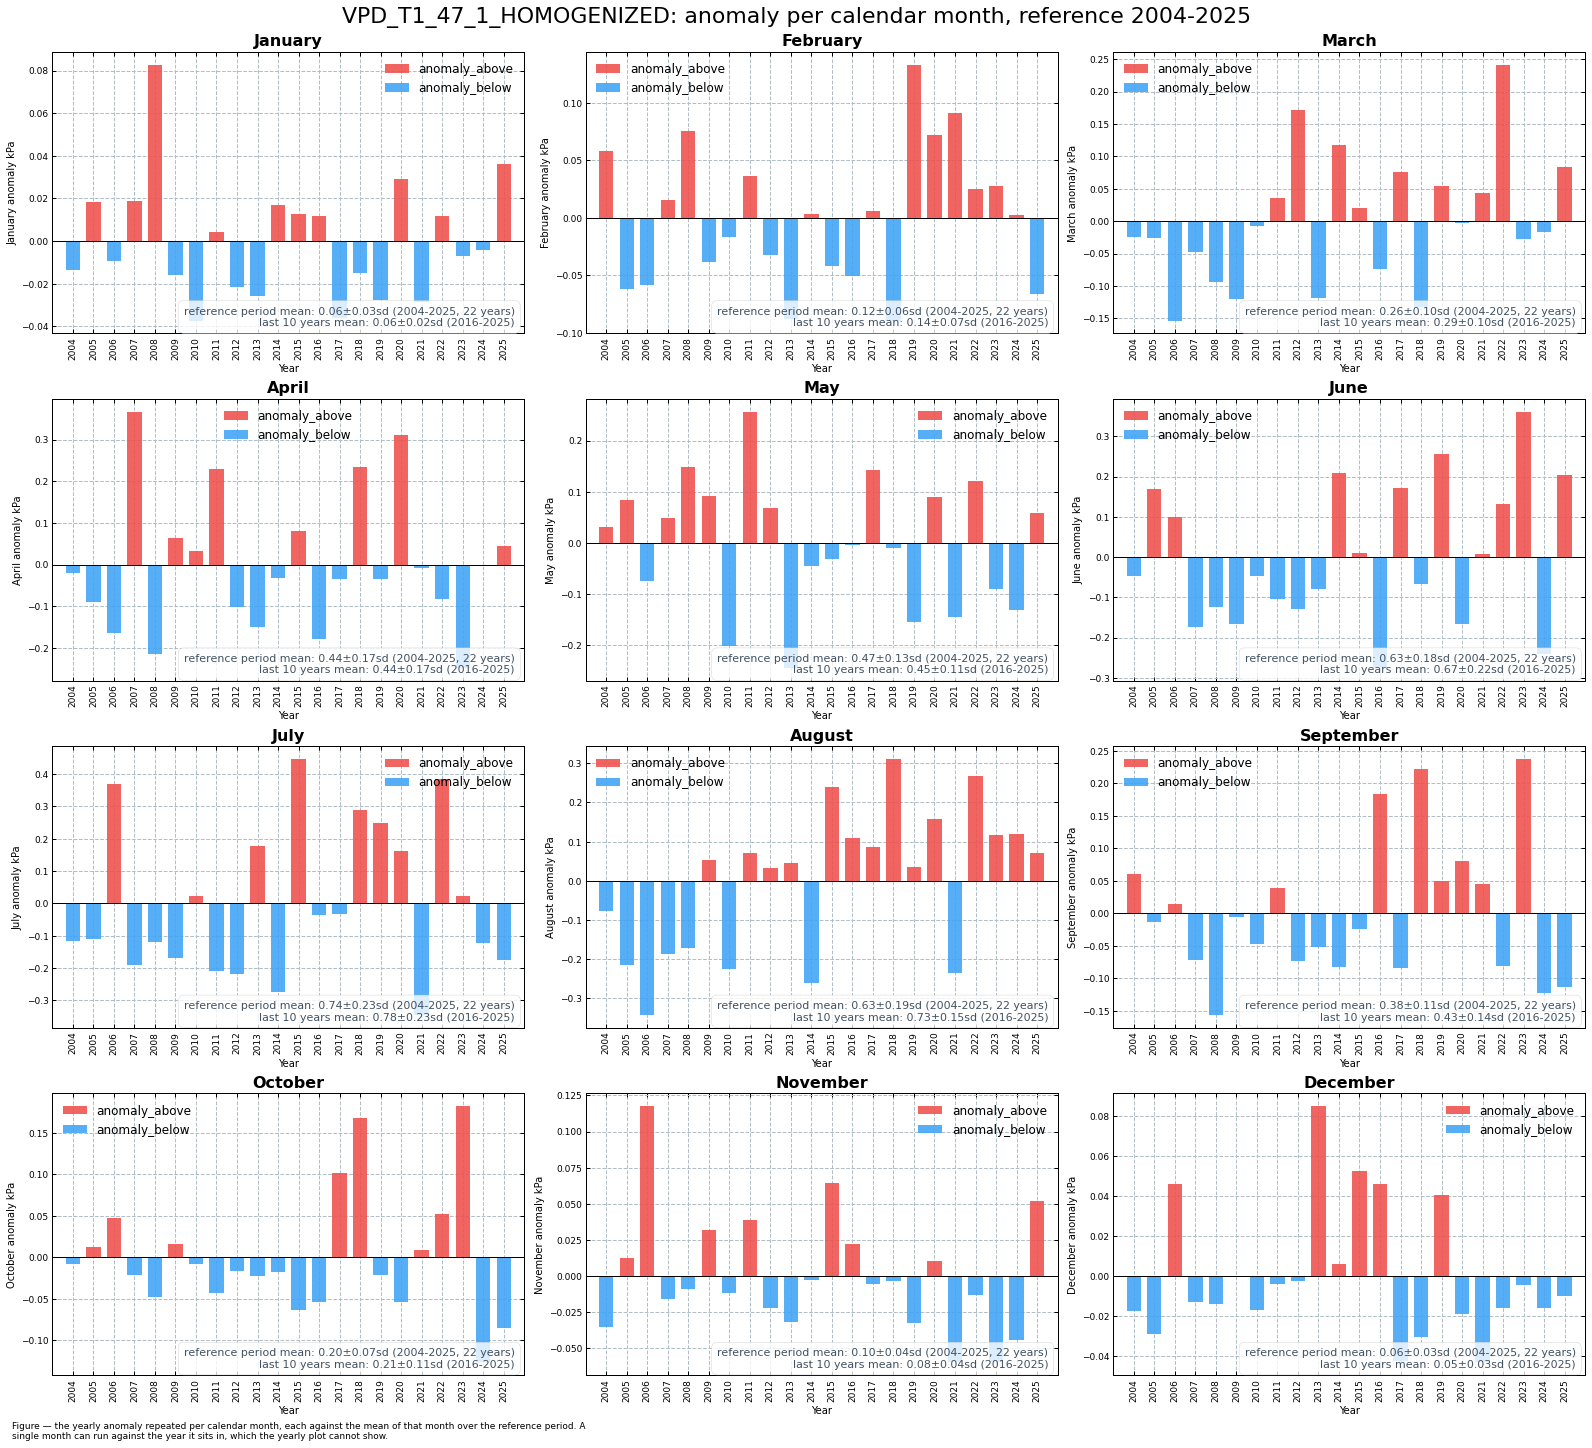

In [38]:
# The same calculation per calendar month, each against the mean of that month over the reference
# period. A single month can run against the year it sits in, which the yearly plot cannot show.
monthly_by_number = per_year_month(series, 'mean', month_names=False)

fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(22, 20), dpi=72, layout="constrained")
fig.suptitle(f"{varname}: anomaly per calendar month, reference "
             f"{REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}", fontsize=22)
for _month, _ax in zip(monthly_by_number.columns, axs.flatten()):
    LongtermAnomaliesYear(series=monthly_by_number[_month].rename(varname),
                          series_label=calendar.month_name[_month],
                          series_units=units,
                          reference_start_year=REFERENCE_START_YEAR,
                          reference_end_year=REFERENCE_END_YEAR).plot(
        ax=_ax, format_style=dv.plotting.FormatStyle(title=calendar.month_name[_month],
                                                     axlabel_fontsize=10, ticks_fontsize=9))
figcap(fig, f"the yearly anomaly repeated per calendar month, each against the mean of that month "
            f"over the reference period. A single month can run against the year it sits in, which "
            f"the yearly plot cannot show.")

## Anomaly by year and month

### 📊 Plot: anomaly by year and month

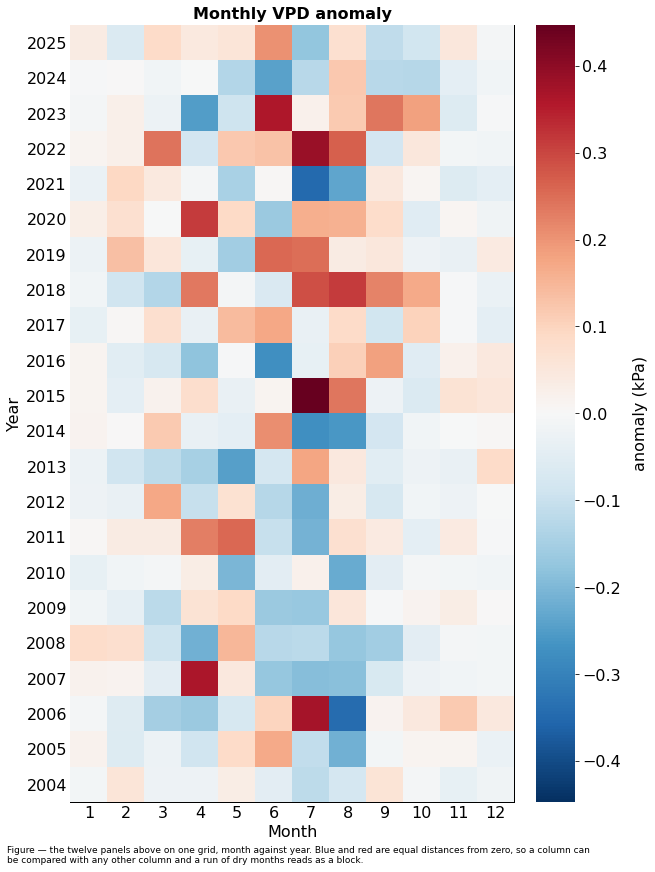

In [39]:
# All twelve panels above on one grid, plus the table behind them. Blue and red are equal distances
# from zero, so a column can be compared with any other column. The anomaly is absolute, so the
# summer months, where VPD is high, carry the largest departures.
anomalies = monthly_avg - monthly_avg.loc[REFERENCE_START_YEAR:REFERENCE_END_YEAR].mean()
_long = monthly_by_number.sub(
    monthly_by_number.loc[REFERENCE_START_YEAR:REFERENCE_END_YEAR].mean()).stack().rename("z").reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
_absmax = _long['z'].abs().max()

fig, ax = plt.subplots(figsize=(9, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=ax, cmap='RdBu_r', vmin=-_absmax, vmax=_absmax,
    xlabel="Month", ylabel="Year", zlabel=f"anomaly ({units})",
    format_style=dv.plotting.FormatStyle(title=f"Monthly {var} anomaly"))
figcap(fig, f"the twelve panels above on one grid, month against year. Blue and red are equal "
            f"distances from zero, so a column can be compared with any other column and a run of "
            f"dry months reads as a block.")

### 📋 Table: anomaly by year and month

In [40]:
display(styled(anomalies, caption=f"monthly {var} anomaly ({units}) against "
                                  f"{REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}, the numbers "
                                  f"behind the grid above",
               cmap='RdBu_r', axis=None, center=True))

Table — monthly VPD anomaly (kPa) against 2004-2025, the numbers behind the grid above



,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
YEAR,,,,,,,,,,,,
2004,-0.01,0.06,-0.02,-0.02,0.03,-0.05,-0.12,-0.08,0.06,-0.01,-0.04,-0.02
2005,0.02,-0.06,-0.03,-0.09,0.08,0.17,-0.11,-0.21,-0.01,0.01,0.01,-0.03
2006,-0.01,-0.06,-0.15,-0.17,-0.08,0.10,0.37,-0.34,0.01,0.05,0.12,0.05
2007,0.02,0.02,-0.05,0.37,0.05,-0.17,-0.19,-0.19,-0.07,-0.02,-0.02,-0.01
2008,0.08,0.08,-0.09,-0.21,0.15,-0.12,-0.12,-0.17,-0.16,-0.05,-0.01,-0.01
2009,-0.02,-0.04,-0.12,0.06,0.09,-0.17,-0.17,0.05,-0.01,0.02,0.03,0.00
2010,-0.04,-0.02,-0.01,0.03,-0.20,-0.05,0.02,-0.23,-0.05,-0.01,-0.01,-0.02
2011,0.00,0.04,0.04,0.23,0.26,-0.10,-0.21,0.07,0.04,-0.04,0.04,-0.00
2012,-0.02,-0.03,0.17,-0.10,0.07,-0.13,-0.22,0.03,-0.07,-0.02,-0.02,-0.00


## Stripes

### 📊 Plot: anomaly stripes

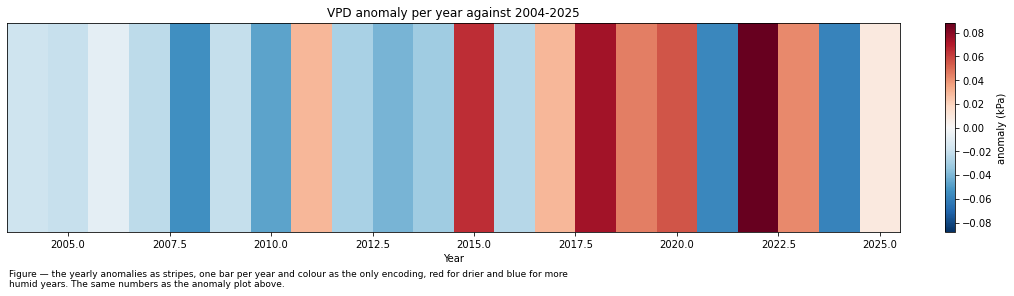

In [41]:
# The yearly anomalies as stripes: the same numbers as the bar plot above, in the form such figures
# are usually published in. One bar per year, no axis, colour is the whole message.
_anomaly = ym - ym.loc[REFERENCE_START_YEAR:REFERENCE_END_YEAR].mean()
_absmax = _anomaly.abs().max()
_cmap = plt.get_cmap('RdBu_r')
_norm = Normalize(vmin=-_absmax, vmax=_absmax)

fig, ax = plt.subplots(figsize=(14, 4), dpi=72, layout="constrained")
ax.bar(_anomaly.index, height=1.0, width=1.0, color=_cmap(_norm(_anomaly.to_numpy())))
ax.set_xlim(_anomaly.index.min() - 0.5, _anomaly.index.max() + 0.5)
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xlabel("Year")
ax.set_title(f"{var} anomaly per year against {REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}")
fig.colorbar(plt.cm.ScalarMappable(norm=_norm, cmap=_cmap), ax=ax, label=f"anomaly ({units})")
figcap(fig, f"the yearly anomalies as stripes, one bar per year and colour as the only encoding, red "
            f"for drier and blue for more humid years. The same numbers as the anomaly plot above.")
fig.show()

## Trend of the yearly means

### 📊 Plot: yearly means and their trend

Theil-Sen slope: +0.031 kPa per decade (95 % interval -0.013 to +0.063)
Kendall tau:     +0.15 (p = 0.3418)


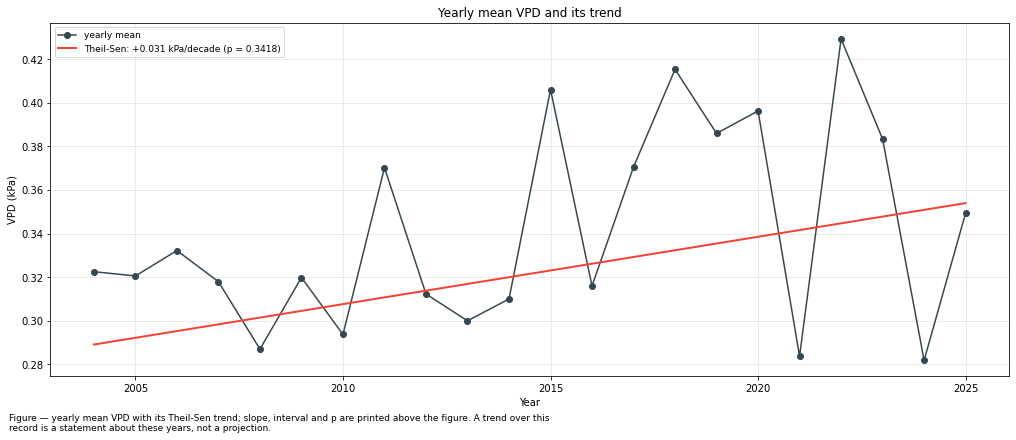

In [42]:
# Trend of the yearly means. Theil-Sen for the slope and Kendall's tau for the significance, see
# the `trend` helper for why. The interval is the 95 % interval of the slope, not of the yearly
# values, and a trend over this record is a statement about these years, not a climate projection.
_fit = trend(ym)
print(f"Theil-Sen slope: {_fit['slope']:+.3f} {units} per decade "
      f"(95 % interval {_fit['low']:+.3f} to {_fit['high']:+.3f})")
print(f"Kendall tau:     {_fit['tau']:+.2f} (p = {_fit['pvalue']:.4f})")

fig, ax = plt.subplots(figsize=(14, 6), dpi=72, layout="constrained")
ax.plot(ym.index, ym, marker='o', color='#37474F', lw=1.5, label="yearly mean")
ax.plot(_fit['fit'].index, _fit['fit'], color='#F44336', lw=2,
        label=f"Theil-Sen: {_fit['slope']:+.3f} {units}/decade (p = {_fit['pvalue']:.4f})")
ax.set_xlabel("Year")
ax.set_ylabel(xlabel)
ax.set_title(f"Yearly mean {var} and its trend")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
figcap(fig, f"yearly mean {var} with its Theil-Sen trend; slope, interval and p are printed above the "
            f"figure. A trend over this record is a statement about these years, not a projection.")
fig.show()

## Trend per calendar month

### 📋 Table: trend per calendar month

In [43]:
# The same slope fitted to each calendar month separately: which part of the year carries the
# change. Bars are drawn solid where Kendall's tau is significant at p < 0.05 and hollow where it is
# not; twelve tests on one record means a single significant month is weak evidence on its own.
_rows = {}
for _month in monthly_by_number.columns:
    _fit = trend(monthly_by_number[_month])
    _rows[calendar.month_abbr[_month]] = {
        f"trend ({units}/decade)": _fit['slope'],
        f"lower 95 % ({units}/decade)": _fit['low'],
        f"upper 95 % ({units}/decade)": _fit['high'],
        "p": _fit['pvalue'],
    }
trends = pd.DataFrame.from_dict(_rows, orient='index')
trends.index.name = "MONTH"

_fmt = {c: "{:.3f}" for c in trends.columns}
_fmt["p"] = "{:.4f}"
display(styled(trends, caption=f"Theil-Sen trend of monthly mean {var} per calendar month with its 95 % "
                               f"interval and Kendall p. Twelve tests on one record, so a single "
                               f"significant month is weak evidence on its own", fmt=_fmt,
               subset=[f"trend ({units}/decade)"], cmap='RdBu_r', center=True))

Table — Theil-Sen trend of monthly mean VPD per calendar month with its 95 % interval and Kendall p.
Twelve tests on one record, so a single significant month is weak evidence on its own



,trend (kPa/decade),lower 95 % (kPa/decade),upper 95 % (kPa/decade),p
MONTH,,,,
Jan,-0.002,-0.020,0.021,0.9113
Feb,0.012,-0.036,0.053,0.7381
Mar,0.057,-0.013,0.125,0.0803
Apr,0.010,-0.101,0.113,0.8236
May,-0.045,-0.139,0.053,0.5031
Jun,0.090,-0.075,0.214,0.2876
Jul,0.030,-0.136,0.232,0.8236
Aug,0.154,0.042,0.273,0.0069
Sep,-0.006,-0.064,0.102,0.9113


### 📊 Plot: trend per calendar month

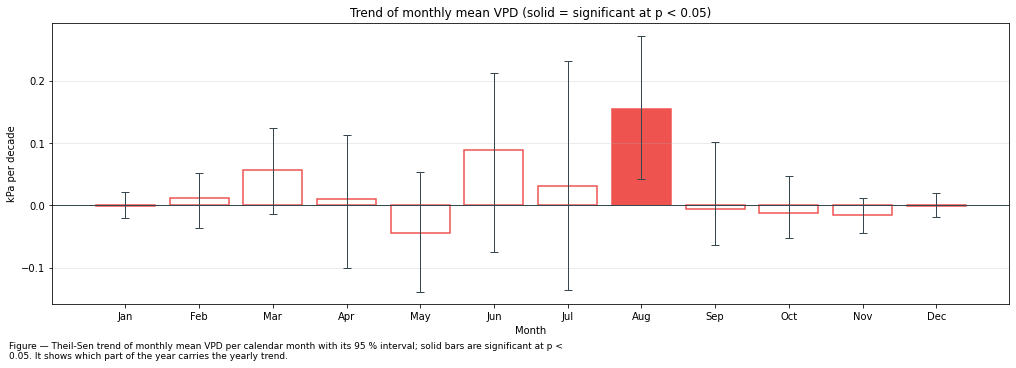

In [44]:
_slope = trends[f"trend ({units}/decade)"]
_significant = trends["p"] < 0.05
fig, ax = plt.subplots(figsize=(14, 5), dpi=72, layout="constrained")
ax.bar(trends.index, _slope, color=['#EF5350' if s else 'white' for s in _significant],
       edgecolor='#EF5350', lw=1.5)
ax.errorbar(trends.index, _slope,
            yerr=[_slope - trends[f"lower 95 % ({units}/decade)"],
                  trends[f"upper 95 % ({units}/decade)"] - _slope],
            fmt='none', ecolor='#37474F', capsize=4, lw=1)
ax.axhline(0, color='#37474F', lw=1)
ax.set_xlabel("Month")
ax.set_ylabel(f"{units} per decade")
ax.set_title(f"Trend of monthly mean {var} (solid = significant at p < 0.05)")
ax.grid(alpha=0.3, axis='y')
figcap(fig, f"Theil-Sen trend of monthly mean {var} per calendar month with its 95 % interval; solid "
            f"bars are significant at p < 0.05. It shows which part of the year carries the yearly "
            f"trend.")
fig.show()

</br>

## Seasonal means and trends

The meteorological seasons: winter (DJF), spring (MAM), summer (JJA) and autumn (SON). A winter is
counted in the year of its January and February, so December belongs to the following winter.
A season enters only when all three of its months are in the record, which leaves out the first
winter and the last December.

In [45]:
_season_of = {12: 'DJF', 1: 'DJF', 2: 'DJF', 3: 'MAM', 4: 'MAM', 5: 'MAM',
              6: 'JJA', 7: 'JJA', 8: 'JJA', 9: 'SON', 10: 'SON', 11: 'SON'}
SEASONS = ['DJF', 'MAM', 'JJA', 'SON']
_monthly = series.resample('ME').mean()
_season_year = _monthly.index.year + (_monthly.index.month == 12)
_grouped = _monthly.groupby([_season_year, _monthly.index.month.map(_season_of)])
seasonal = _grouped.mean().where(_grouped.count() == 3).unstack()[SEASONS]
seasonal.index.name = 'YEAR'
seasonal = seasonal.loc[FIRST_YEAR:LAST_YEAR]

### 📋 Table: seasonal means and their trends

In [46]:
_rows = {}
for _s in SEASONS:
    _fit = trend(seasonal[_s].dropna())
    _rows[_s] = {f"mean ({units})": seasonal[_s].mean(), f"trend ({units}/decade)": _fit['slope'],
                 f"lower 95 % ({units}/decade)": _fit['low'], f"upper 95 % ({units}/decade)": _fit['high'],
                 "p": _fit['pvalue'], "seasons": int(seasonal[_s].notna().sum())}
SEASON_TRENDS = pd.DataFrame.from_dict(_rows, orient='index')
SEASON_TRENDS.index.name = 'SEASON'
_fmt = {c: "{:.3f}" for c in SEASON_TRENDS.columns}
_fmt.update({"p": "{:.4f}", "seasons": "{:.0f}"})
display(styled(SEASON_TRENDS, caption=f"mean {var} per season and its Theil-Sen trend with the 95 % interval "
                                      f"and Kendall p, over the complete seasons of {FIRST_YEAR}-{LAST_YEAR}",
               fmt=_fmt, subset=[f"trend ({units}/decade)"], cmap='RdBu_r', center=True))

Table — mean VPD per season and its Theil-Sen trend with the 95 % interval and Kendall p, over the
complete seasons of 2004-2025



,mean (kPa),trend (kPa/decade),lower 95 % (kPa/decade),upper 95 % (kPa/decade),p,seasons
SEASON,,,,,,
DJF,0.080,0.007,-0.020,0.023,0.6545,21
MAM,0.391,0.018,-0.062,0.066,0.5770,22
JJA,0.663,0.105,-0.001,0.205,0.0708,22
SON,0.225,-0.002,-0.036,0.038,0.8236,22


### 📊 Plot: seasonal anomalies and their trends

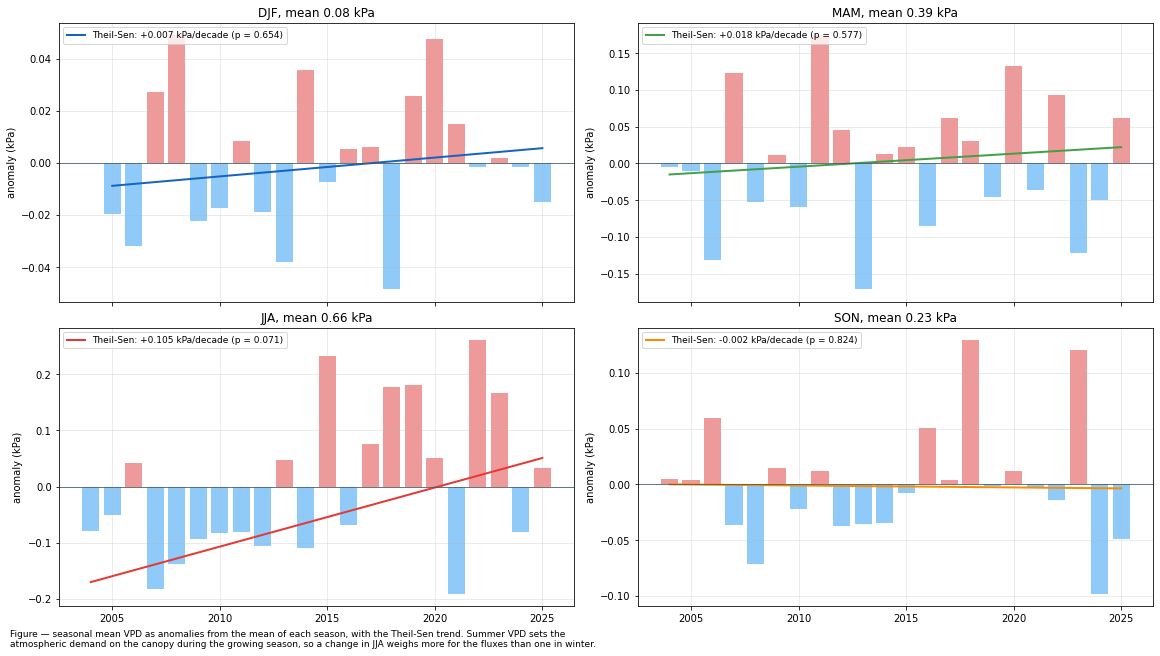

In [47]:
_colors = {'DJF': '#1565C0', 'MAM': '#43A047', 'JJA': '#E53935', 'SON': '#FB8C00'}
fig, axs = plt.subplots(2, 2, figsize=(16, 9), dpi=72, sharex=True, layout="constrained")
for _ax, _s in zip(axs.flat, SEASONS):
    _x = seasonal[_s].dropna()
    _anom = _x - _x.mean()
    _fit = trend(_x)
    _ax.bar(_anom.index, _anom, color=np.where(_anom > 0, '#EF9A9A', '#90CAF9'))
    _ax.plot(_fit['fit'].index, _fit['fit'] - _x.mean(), color=_colors[_s], lw=2,
             label=f"Theil-Sen: {_fit['slope']:+.3f} {units}/decade (p = {_fit['pvalue']:.3f})")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.set_title(f"{_s}, mean {_x.mean():.2f} {units}")
    _ax.set_ylabel(f"anomaly ({units})")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9, loc='upper left')
figcap(fig, f"seasonal mean {var} as anomalies from the mean of each season, with the Theil-Sen trend. "
            f"Summer VPD sets the atmospheric demand on the canopy during the growing season, so a "
            f"change in JJA weighs more for the fluxes than one in winter.")
fig.show()

## Trends of the daily maximum and the threshold days

The mean daily maximum describes the afternoon, when VPD and the atmospheric demand on the canopy are
highest; the threshold-day counts describe how often a given level is reached. Both rest on the high
end of the distribution, which the homogenisation affects less than the low end.

In [48]:
DAILY_STATS = pd.DataFrame({f"mean daily maximum ({units})": per_year(daily['max'], 'mean'),
                            f"mean daily mean ({units})": per_year(daily['mean'], 'mean')})

### 📋 Table: trends of the daily maximum and the threshold days

In [49]:
_rows = {}
for _c in DAILY_STATS.columns:
    _fit = trend(DAILY_STATS[_c])
    _rows[_c] = {"mean": DAILY_STATS[_c].mean(), "trend per decade": _fit['slope'],
                 "lower 95 %": _fit['low'], "upper 95 %": _fit['high'], "p": _fit['pvalue']}
for _c in indices.columns:
    _fit = trend(indices[_c].fillna(0))
    _rows[f"{_c} (days)"] = {"mean": indices[_c].fillna(0).mean(), "trend per decade": _fit['slope'],
                             "lower 95 %": _fit['low'], "upper 95 %": _fit['high'], "p": _fit['pvalue']}
EXTREME_TRENDS = pd.DataFrame.from_dict(_rows, orient='index')
EXTREME_TRENDS.index.name = 'QUANTITY'
_fmt = {c: "{:.2f}" for c in EXTREME_TRENDS.columns}
_fmt["p"] = "{:.4f}"
display(styled(EXTREME_TRENDS, caption=f"mean and Theil-Sen trend per decade, with the 95 % interval and "
                                       f"Kendall p, of the yearly mean daily maximum and daily mean "
                                       f"({units}) and of the threshold-day counts (days), "
                                       f"{FIRST_YEAR}-{LAST_YEAR}",
               fmt=_fmt, subset=["trend per decade"], cmap='RdBu_r', center=True))

Table — mean and Theil-Sen trend per decade, with the 95 % interval and Kendall p, of the yearly
mean daily maximum and daily mean (kPa) and of the threshold-day counts (days), 2004-2025



,mean,trend per decade,lower 95 %,upper 95 %,p
QUANTITY,,,,,
mean daily maximum (kPa),0.69,0.04,-0.02,0.09,0.2628
mean daily mean (kPa),0.34,0.03,-0.01,0.06,0.3418
days max >= 1 kPa (days),96.86,10.00,-1.11,20.00,0.0749
days max >= 2 kPa (days),17.82,3.33,-1.82,8.18,0.1341
days max >= 3 kPa (days),2.18,0.00,0.00,2.00,0.3249
days mean >= 1 kPa (days),28.23,10.00,1.25,16.67,0.0277
saturated days (max < 0.1 kPa) (days),63.55,3.33,-5.45,11.00,0.4123


### 📊 Plot: yearly mean daily maximum and dry days with their trends

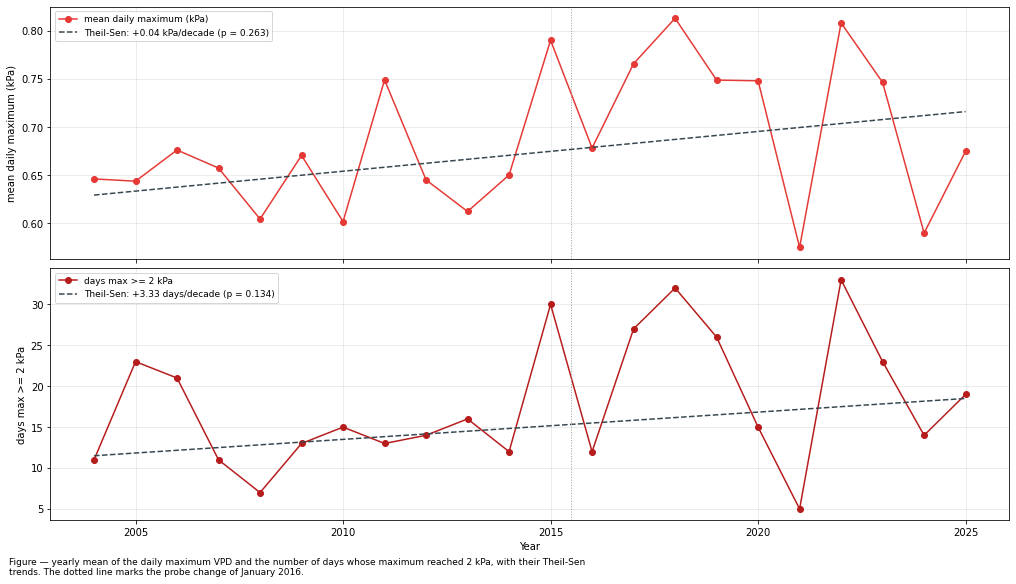

In [50]:
_high_col = f"days max >= {VPD_DRY_THRESHOLDS[1]:g} {units}"
_panels = [(DAILY_STATS[f"mean daily maximum ({units})"], f"mean daily maximum ({units})", '#E53935', units),
           (indices[_high_col].fillna(0), _high_col, '#B71C1C', "days")]
fig, axs = plt.subplots(2, 1, figsize=(14, 8), dpi=72, sharex=True, layout="constrained")
for _ax, (_s, _label, _color, _u) in zip(axs, _panels):
    _fit = trend(_s)
    _ax.plot(_s.index, _s, marker='o', color=_color, lw=1.5, label=_label)
    _ax.plot(_fit['fit'].index, _fit['fit'], color='#37474F', lw=1.5, ls='--',
             label=f"Theil-Sen: {_fit['slope']:+.2f} {_u}/decade (p = {_fit['pvalue']:.3f})")
    _ax.axvline(2015.5, color='#9E9E9E', lw=1, ls=':')
    _ax.set_ylabel(_label)
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9, loc='upper left')
axs[-1].set_xlabel("Year")
figcap(fig, f"yearly mean of the daily maximum {var} and the number of days whose maximum reached "
            f"{VPD_DRY_THRESHOLDS[1]:g} {units}, with their Theil-Sen trends. The dotted line marks the "
            f"probe change of January 2016.")
fig.show()

# Cumulative plot

## 📊 Plot: cumulative VPD per year

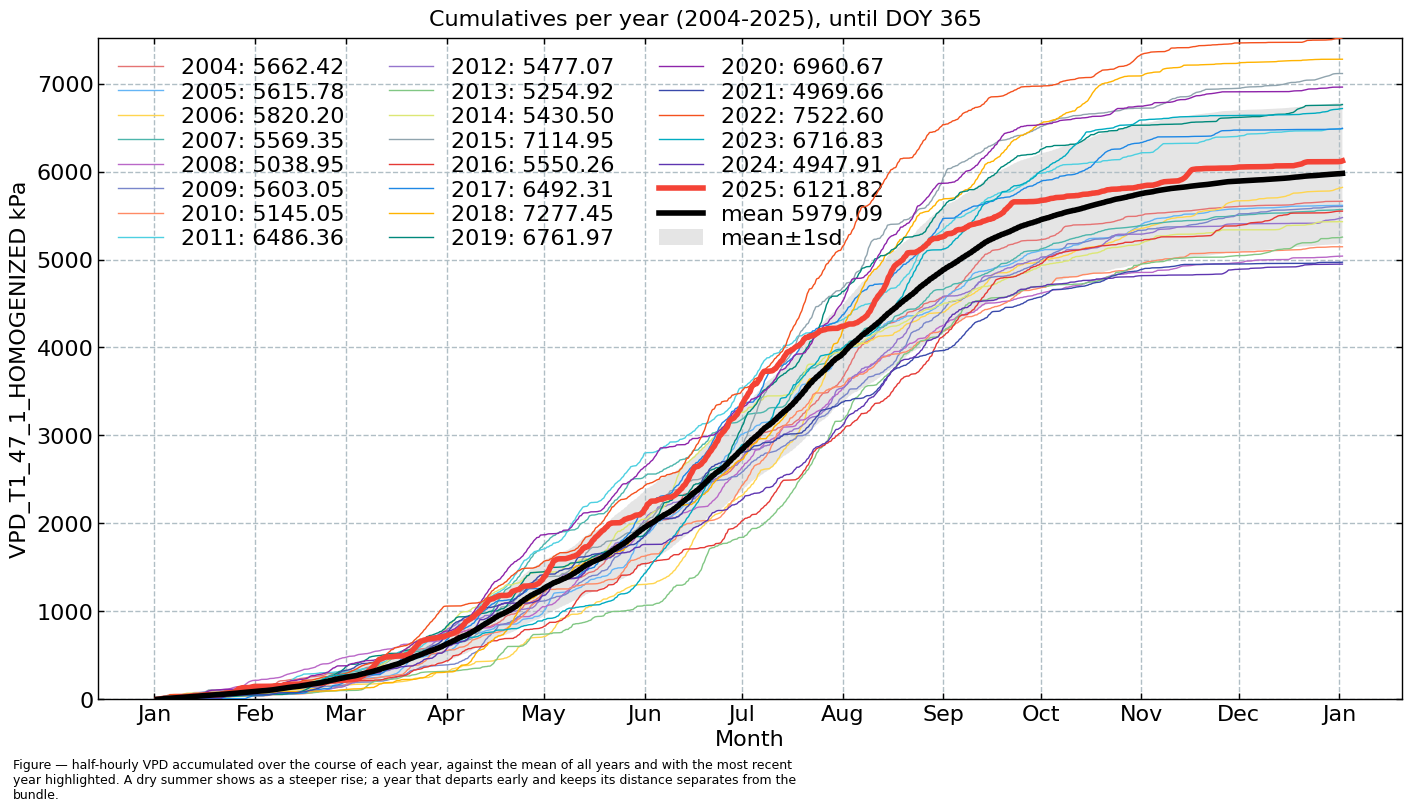

In [51]:
_cumulative = CumulativeYear(
    series=series,
    series_units=units,
    start_year=FIRST_YEAR,
    end_year=LAST_YEAR,
    show_reference=True,
    excl_years_from_reference=None,
    highlight_year=LAST_YEAR)
_cumulative.plot(highlight_year_color='#F44336')
figcap(_cumulative.fig,
       f"half-hourly {var} accumulated over the course of each year, against the mean of all years and "
       f"with the most recent year highlighted. A dry summer shows as a steeper rise; a year that "
       f"departs early and keeps its distance separates from the bundle.")

</br>

# Comparison with the MeteoSwiss reference station

The MeteoSwiss station Lägern is 2.5 km from the tower, about 400 m lower, and is operated by a
different institution. Its own `TA` and `RH` give a reference VPD by the same formula, and the
difference against it removes most of the weather and leaves the instruments. The elevation
difference makes an offset expected; what matters is whether the offset changes at the probe change
of 21 January 2016.

That comparison is an **independent test** of the homogenisation: notebooks `02` and `04` fitted
their 2016 transfers against NABEL on the tower, not against Lägern. Only records computed from two
measurements (flag `0`) enter, and the residual is split into night and day, because the
radiation-shield term of the `TA` homogenisation acts only in sunlight. The full scoring of the
three possible bases is in the product notebook `07`.

In [52]:
# The reference product is written by 10_METEO/10_REFERENCE and is stored on TIMESTAMP_END, so it
# is shifted onto the product's TIMESTAMP_MIDDLE before anything is compared. Its VPD is computed
# from its own TA and RH with the formula the product uses.
REFDIR = r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\10_REFERENCE"
REFFILE = "MeteoSwiss_LAE_30MIN_2004-2026.09.parquet"
_ref_in = pd.read_parquet(Path(REFDIR) / REFFILE)[['TA_LAE_MS', 'RH_LAE_MS']].dropna()
_ref_in.index = _ref_in.index - pd.Timedelta('15min')
_reference = dv.variables.calc_vpd_from_ta_rh(df=_ref_in, rh_col='RH_LAE_MS', ta_col='TA_LAE_MS')
assert _reference.between(*LIMITS).all(), "the reference VPD is outside the physical limits"

# Records computed from two measurements only, from both columns, so the step and its removal are
# visible side by side.
_meas = df[flagname] == 0
both = pd.concat([df.loc[_meas, varname_measured].rename('measured'),
                  df.loc[_meas, varname].rename('homogenised'),
                  _reference.rename('reference')], axis=1, sort=True).dropna()
assert len(both) > 100_000, f"only {len(both)} overlapping half-hours with the reference station"

residual = (both['homogenised'] - both['reference']).rename('residual')
print(f"Overlap:  {len(both):,} half-hours from measured TA and RH, "
      f"{both.index[0]:%Y-%m-%d} to {both.index[-1]:%Y-%m-%d}")
for _name in ('measured', 'homogenised'):
    _r = both[_name] - both['reference']
    print(f"Residual ({_name:12s}): {_r.mean():+.3f} {units} +/- {_r.std():.3f} {units} SD, "
          f"ratio of means {both[_name].mean() / both['reference'].mean():.3f}")
print(f"Correlation: r = {both['homogenised'].corr(both['reference']):.4f}")

Overlap:  368,789 half-hours from measured TA and RH, 2004-09-20 to 2025-12-31
Residual (measured    ): +0.024 kPa +/- 0.100 kPa SD, ratio of means 1.073
Residual (homogenised ): +0.013 kPa +/- 0.098 kPa SD, ratio of means 1.040
Correlation: r = 0.9794


## Residual over time

### 📊 Plot: residual against the reference station

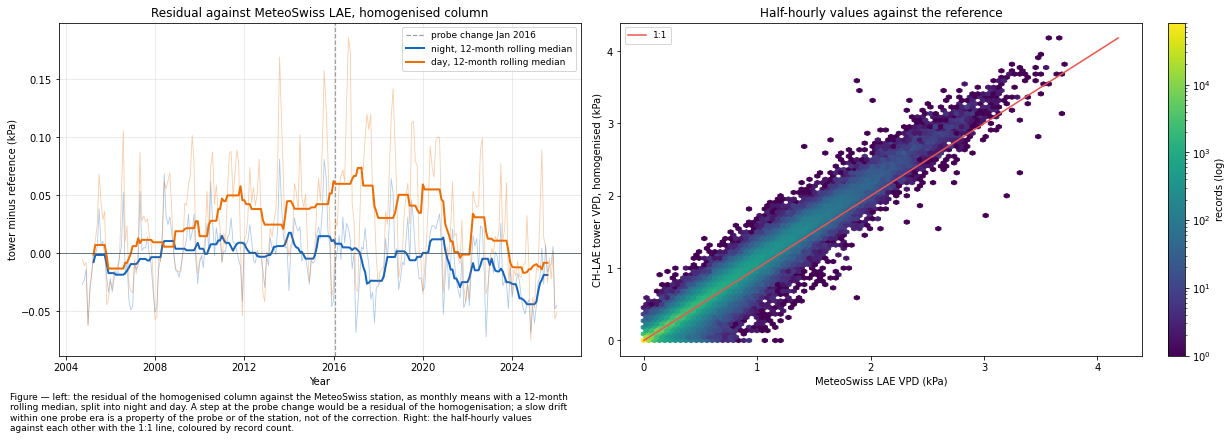

In [53]:
# Left: the residual as monthly means, separately for night and day, each with a 12-month rolling
# median. Right: the two series against each other, with the 1:1 line for orientation.
_pot = dv.variables.potrad(timestamp_index=both.index, lat=SITE_LAT, lon=SITE_LON,
                           utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)
_is_night = _pot <= 0

fig, axs = plt.subplots(ncols=2, figsize=(17, 6), dpi=72, layout="constrained")
_break = df.index[df[sourcename] == 0][0]
axs[0].axvline(_break, color='#9E9E9E', lw=1.2, ls='--', label=f"probe change {_break:%b %Y}")
for _label, _mask, _colour in [('night', _is_night, '#1565C0'), ('day', ~_is_night, '#EF6C00')]:
    _r = residual[_mask].resample('ME').mean()
    axs[0].plot(_r.index, _r, color=_colour, lw=0.8, alpha=0.35)
    axs[0].plot(_r.index, _r.rolling(12, center=True).median(), color=_colour, lw=2,
                label=f"{_label}, 12-month rolling median")
axs[0].axhline(0, color='#455A64', lw=0.8)
axs[0].set_xlabel("Year")
axs[0].set_ylabel(f"tower minus reference ({units})")
axs[0].set_title("Residual against MeteoSwiss LAE, homogenised column")
axs[0].grid(alpha=0.3)
axs[0].legend(fontsize=9)

_hb = axs[1].hexbin(both['reference'], both['homogenised'], gridsize=80, bins='log', cmap='viridis')
_line = [0, both.max().max()]
axs[1].plot(_line, _line, color='#EF5350', lw=1.5, label="1:1")
axs[1].set_xlabel(f"MeteoSwiss LAE {var} ({units})")
axs[1].set_ylabel(f"CH-LAE tower {var}, homogenised ({units})")
axs[1].set_title("Half-hourly values against the reference")
axs[1].legend(fontsize=9)
fig.colorbar(_hb, ax=axs[1], label="records (log)")
figcap(fig, f"left: the residual of the homogenised column against the MeteoSwiss station, as monthly "
            f"means with a 12-month rolling median, split into night and day. A step at the probe "
            f"change would be a residual of the homogenisation; a slow drift within one probe era is "
            f"a property of the probe or of the station, not of the correction. Right: the "
            f"half-hourly values against each other with the 1:1 line, coloured by record count.")

### 📋 Table: step across the probe change

In [54]:
# The step, stated rather than left to the eye. Three complete years either side, so the January
# 2016 changeover does not sit inside a compared window.
_yr = _break.year
_pre = (both.index.year >= _yr - 3) & (both.index.year <= _yr - 1)
_post = (both.index.year >= _yr + 1) & (both.index.year <= _yr + 3)
_rows = []
for _wname, _wmask in [('all hours', np.ones(len(both), bool)),
                       ('night', _is_night.to_numpy()), ('day', (~_is_night).to_numpy())]:
    for _col in ('measured', 'homogenised'):
        _r = both[_col] - both['reference']
        _rows.append({'window': _wname, 'column': _col,
                      f'{_yr - 3}-{_yr - 1} ({units})': _r[_pre & _wmask].mean(),
                      f'{_yr + 1}-{_yr + 3} ({units})': _r[_post & _wmask].mean(),
                      f'step ({units})': _r[_post & _wmask].mean() - _r[_pre & _wmask].mean()})
display(styled(pd.DataFrame(_rows).set_index(['window', 'column']),
               caption=f"the step across the probe change, measured against MeteoSwiss over three "
                       f"complete years either side, on the measured and the homogenised column",
               fmt="{:.3f}", subset=[f'step ({units})'], cmap='RdBu_r', center=True))

Table — the step across the probe change, measured against MeteoSwiss over three complete years
either side, on the measured and the homogenised column



### 📋 Table: residual against the reference station per year

In [55]:
_yearly_residual = pd.DataFrame({
    f"mean residual ({units})": per_year(residual, 'mean'),
    f"night ({units})": per_year(residual[_is_night], 'mean'),
    f"day ({units})": per_year(residual[~_is_night], 'mean'),
    "ratio of means": per_year(both['homogenised'], 'mean') / per_year(both['reference'], 'mean'),
    "overlapping half-hours": per_year(residual, 'count'),
})
_fmt = {c: "{:.3f}" for c in _yearly_residual.columns}
_fmt["overlapping half-hours"] = "{:.0f}"
display(styled(_yearly_residual, caption="residual of the homogenised column against the MeteoSwiss station "
                                         "per year, split into night and day, with the ratio of the "
                                         "yearly means. VPD errors grow with VPD itself, so a dry year "
                                         "carries a larger difference at the same ratio", fmt=_fmt,
               subset=[f"night ({units})", f"day ({units})"], cmap='RdBu_r', center=True))

Table — residual of the homogenised column against the MeteoSwiss station per year, split into night
and day, with the ratio of the yearly means. VPD errors grow with VPD itself, so a dry year carries
a larger difference at the same ratio



,mean residual (kPa),night (kPa),day (kPa),ratio of means,overlapping half-hours
YEAR,,,,,
2004,-0.029,-0.033,-0.023,0.775,4922
2005,0.001,-0.010,0.011,1.005,17486
2006,-0.006,-0.021,0.008,0.983,17493
2007,0.005,-0.008,0.016,1.015,17507
2008,0.014,0.003,0.024,1.051,17548
2009,0.017,-0.000,0.033,1.057,17034
2010,0.024,0.010,0.037,1.090,17351
2011,0.026,0.001,0.048,1.075,17463
2012,0.018,-0.000,0.035,1.063,16285


## Trend of the tower against the reference station

A trend that comes from the probes or the homogenisation rather than from the climate would show as
a trend in the difference between the tower and the MeteoSwiss station LAE. Yearly means over the
years in which the reference is at least 95 % complete.

### 📋 Table: trends of the tower, the reference and their difference

In [56]:
_ref = _reference.loc[str(FIRST_YEAR):str(LAST_YEAR)]
_coverage = _ref.resample('YE').count() / series.resample('YE').count().reindex(_ref.resample('YE').count().index)
_coverage.index = _coverage.index.year
_years = _coverage.index[_coverage >= 0.95]
REF_YEARLY = pd.DataFrame({
    'tower, homogenised': ym.reindex(_years),
    'tower, as measured': per_year(df[varname_measured], 'mean').reindex(_years),
    'MeteoSwiss LAE': per_year(_ref, 'mean').reindex(_years),
})
REF_YEARLY['homogenised minus reference'] = REF_YEARLY['tower, homogenised'] - REF_YEARLY['MeteoSwiss LAE']
REF_YEARLY['measured minus reference'] = REF_YEARLY['tower, as measured'] - REF_YEARLY['MeteoSwiss LAE']
_rows = {}
for _c in REF_YEARLY.columns:
    _fit = trend(REF_YEARLY[_c].dropna())
    _rows[_c] = {f"trend ({units}/decade)": _fit['slope'], f"lower 95 % ({units}/decade)": _fit['low'],
                 f"upper 95 % ({units}/decade)": _fit['high'], "p": _fit['pvalue']}
REF_TRENDS = pd.DataFrame.from_dict(_rows, orient='index')
REF_TRENDS.index.name = 'SERIES'
_fmt = {c: "{:.3f}" for c in REF_TRENDS.columns}
_fmt["p"] = "{:.4f}"
display(styled(REF_TRENDS, caption=f"Theil-Sen trend of the yearly mean {var} of the tower, the reference "
                                   f"station and their differences, over the {len(_years)} years in which "
                                   f"the reference is at least 95 % complete. A trend in the difference "
                                   f"of the homogenised series is the part of the tower trend that the "
                                   f"reference does not share", fmt=_fmt,
               subset=[f"trend ({units}/decade)"], cmap='RdBu_r', center=True))

Table — Theil-Sen trend of the yearly mean VPD of the tower, the reference station and their
differences, over the 21 years in which the reference is at least 95 % complete. A trend in the
difference of the homogenised series is the part of the tower trend that the reference does not
share



,trend (kPa/decade),lower 95 % (kPa/decade),upper 95 % (kPa/decade),p
SERIES,,,,
"tower, homogenised",0.033,-0.012,0.066,0.2945
"tower, as measured",0.023,-0.018,0.058,0.3536
MeteoSwiss LAE,0.031,-0.004,0.063,0.0745
homogenised minus reference,-0.000,-0.018,0.015,0.9287
measured minus reference,-0.010,-0.025,0.006,0.1245


### 📊 Plot: yearly means of the tower and the reference station

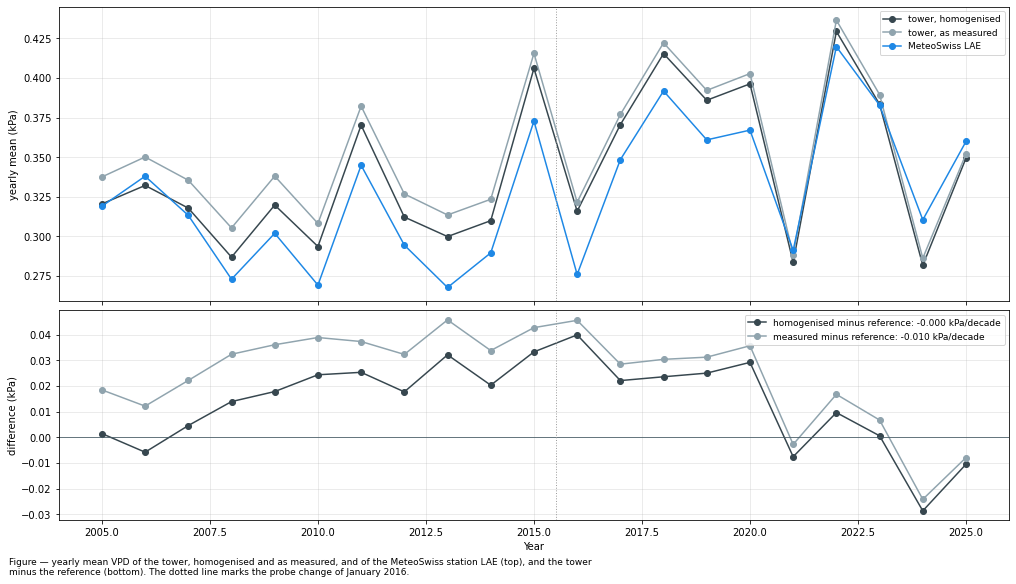

In [57]:
fig, axs = plt.subplots(2, 1, figsize=(14, 8), dpi=72, sharex=True, layout="constrained",
                        height_ratios=[1.4, 1])
for _c, _color in (('tower, homogenised', '#37474F'), ('tower, as measured', '#90A4AE'),
                   ('MeteoSwiss LAE', '#1E88E5')):
    axs[0].plot(REF_YEARLY.index, REF_YEARLY[_c], marker='o', lw=1.5, color=_color, label=_c)
axs[0].set_ylabel(f"yearly mean ({units})")
for _c, _color in (('homogenised minus reference', '#37474F'), ('measured minus reference', '#90A4AE')):
    _fit = trend(REF_YEARLY[_c].dropna())
    axs[1].plot(REF_YEARLY.index, REF_YEARLY[_c], marker='o', lw=1.5, color=_color,
                label=f"{_c}: {_fit['slope']:+.3f} {units}/decade")
axs[1].axhline(0, color='#455A64', lw=0.8)
axs[1].set_ylabel(f"difference ({units})")
axs[1].set_xlabel("Year")
for _ax in axs:
    _ax.axvline(2015.5, color='#9E9E9E', lw=1, ls=':')
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
figcap(fig, f"yearly mean {var} of the tower, homogenised and as measured, and of the MeteoSwiss station "
            f"LAE (top), and the tower minus the reference (bottom). The dotted line marks the probe "
            f"change of January 2016.")
fig.show()

</br>

# Appendix: single-year detail

One figure per year for the last `N_DETAIL_YEARS` years, drawn only when `SHOW_PER_YEAR_DETAIL` is
set in the Settings cell. They repeat the distributions per month year by year and are kept at the
end because they are detail, not overview.

## Single years per month

### 📊 Plot: distribution per month, last years

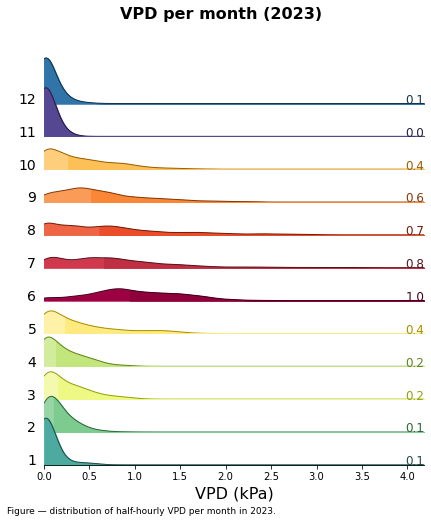

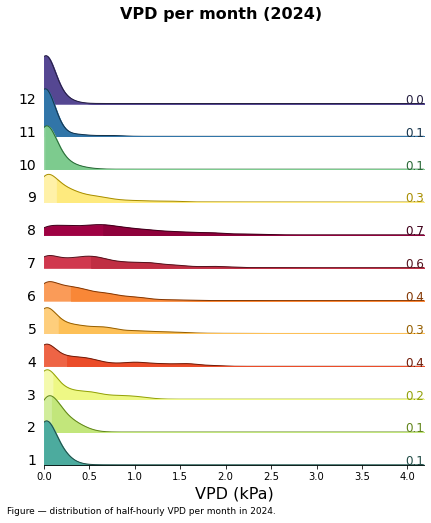

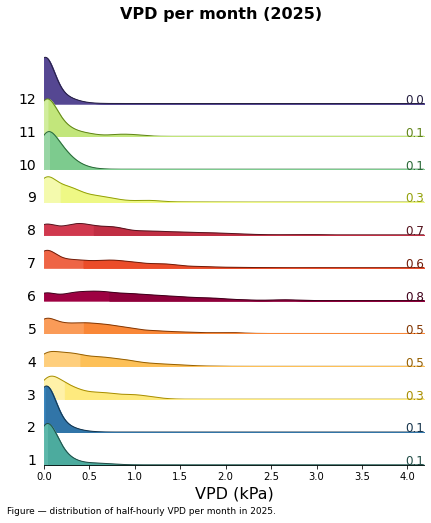

In [58]:
if SHOW_PER_YEAR_DETAIL:
    for uy in sorted(series.index.year.unique())[-N_DETAIL_YEARS:]:
        series_yr = series.loc[series.index.year == uy].copy()
        rp = dv.plotting.RidgeLinePlot(series=series_yr)
        rp.plot(
            how='monthly',
            kd_kwargs=KD_KWARGS,  # params from scikit KernelDensity as dict
            xlim=xlim,  # min/max as list
            ylim=[0, 6],  # min/max as list
            hspace=-0.6,  # overlap
            fig_width=6,
            fig_height=7,
            shade_percentile=0.5,
            show_mean_line=False,
            format_style=dv.plotting.FormatStyle(xlabel=xlabel, title=f"{var} per month ({uy})"),
            fig_dpi=72,
            showplot=True,
            ascending=False
        )
        figcap(rp.fig, f"distribution of half-hourly {var} per month in {uy}.")

</br>

# End of notebook

In [59]:
dt_string = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Finished. {dt_string}")

Finished. 2026-10-30 19:30:25
